# Proyecto Final de Bioinformática
## Reanálisis crítico del transcriptoma de macrófagos tratados con hidrogeles cargados con flavonoides (GEO: GSE260761)

Alumna: Candela Ahumada Horgan · Carrera: Bioingeniería (4.º año) · Universidad: UNSTA
Docente: Lic. Esp. Ignacio García Labari · Materia: Bioinformática 2026

---

### Índice
0. Pregunta de investigación e hipótesis
1. Contexto biológico: de dónde salen estos datos
2. Preparación del entorno
3. Carga de los datos desde GEO
4. Preparación y limpieza de los datos
5. Normalización
6. Control de calidad y detección de una contaminación
7. Reducción de dimensionalidad: PCA
8. Agrupamiento (clustering) de muestras
9. Expresión diferencial (DESeq2)
10. Comparación entre los cuatro flavonoides
11. Análisis funcional con bases de datos (KEGG, GO, Reactome)
12. Puesta a prueba de la hipótesis del paper (CD36 → PPAR → M2)
13. Machine learning: ¿se puede reconocer el tratamiento a partir del transcriptoma?
14. Del ratón al humano: análisis de secuencias, alineamiento y filogenia de HO-1
15. Discusión y conclusiones
16. Mapa de conceptos de la materia aplicados en este trabajo
17. Referencias

> Formato de cada paso. Todas las secciones siguen la misma estructura para que se vea el razonamiento y no solo el código:
> Objetivo, Por qué lo hago (la justificación teórica), Método y ¿Qué se observa? (la interpretación de los resultados). En el código, los comentarios con # explican las líneas más importantes.

## 0. Pregunta de investigación e hipótesis

**Trabajo de partida.** El paper de referencia es: Zeng Q., Du S., Yuan R., Zeng Y., Li X., Wu Y.-W., Chen K., Tao L., Tang Z. y Deng X. (2025). *Self-Healing Hydrogel Dressing with Solubilized Flavonoids for Whole Layer Regeneration of Diabetic Wound*. Advanced Healthcare Materials, 14, 2500734. DOI: 10.1002/adhm.202500734. Se publicó en marzo de 2025 y los autores trabajan en la Escuela y Hospital de Estomatología de la Universidad de Pekín (Beijing, China).

El objetivo del paper es desarrollar un apósito para heridas de pie diabético. Los autores diseñaron un hidrogel que solubiliza flavonoides y lo cargaron con cuatro de ellos: catequina, quercetina, miricetina y dihidromiricetina. Cultivaron macrófagos RAW264.7 dentro de los hidrogeles durante 24 h y secuenciaron su ARN (RNA-seq). En el paper solo analizan en profundidad la catequina, y proponen el mecanismo CD36 → metabolismo lipídico → PPAR → polarización M2, apoyado en un enriquecimiento de procesos de "catabolismo lipídico" y "actividad triglicérido lipasa".

¿Qué queda sin responder? Los datos de los otros tres flavonoides están depositados en GEO pero el paper no los compara entre sí. Además, el análisis publicado usa un umbral permisivo (p < 0,05 sin corrección por comparaciones múltiples).

**Pregunta central:**
> ¿Los cuatro flavonoides producen una respuesta transcriptómica común o distinta en los macrófagos? ¿Esa respuesta es la que propone el paper (CD36/PPAR/M2) o es otra? Y los genes clave de esa respuesta, ¿están conservados en el ser humano como para pensar en una aplicación clínica?

**Hipótesis de trabajo:**
- **H1.** Al ser todos polifenoles antioxidantes, los cuatro flavonoides deberían activar un programa de defensa frente al estrés oxidativo (vía Nrf2), con intensidad diferente según su estructura química.
- **H2.** Si el mecanismo CD36/PPAR/M2 es real, deberían verse cambios consistentes en genes de esa vía y de marcadores M2, en especial con catequina.
- **H3.** Las proteínas efectoras de la respuesta (por ejemplo, la hemo oxigenasa-1) están muy conservadas entre ratón y humano, lo que da relevancia traslacional a lo observado en células murinas.

**Utilidad real del trabajo.** Las heridas crónicas del paciente diabético son un problema clínico grave y el estrés oxidativo es uno de sus motores. Saber qué flavonoide activa con más fuerza la defensa antioxidante y si las conclusiones publicadas se sostienen sirve para decidir qué formulación vale la pena llevar a ensayos posteriores.

## 1. Contexto biológico: de dónde salen estos datos

Transcriptoma y RNA-seq. El transcriptoma es el conjunto de todos los ARN presentes en una célula en un momento dado. Es dinámico: cambia con el tipo celular y con las condiciones. Por eso es la "foto" ideal para ver cómo responde un macrófago a un tratamiento. La RNA-seq cuantifica ese ARN: se extrae, se convierte en ADNc, se fragmenta, se secuencia (acá con Illumina NovaSeq, lecturas pareadas de 150 pb) y luego cada lectura se ubica en el genoma de referencia.

El flujo de trabajo previo a los datos que uso. Según los métodos del paper, las lecturas crudas (FASTQ) pasaron por un control de calidad y limpieza con *fastp* (se descartan lecturas con baja calidad Phred), se mapearon al genoma de ratón con *HISAT2* y se contó cuántas lecturas caen en cada gen con *HTSeq-count*. Es exactamente el mismo flujo que se arma en Galaxy para un análisis transcriptómico (control de calidad → mapeo → conteo). Yo parto del producto final de ese flujo: la matriz de conteos, depositada en la base de datos GEO del NCBI.

Diseño experimental. 5 condiciones × 3 réplicas biológicas = 15 muestras:

| Código en GEO | Tratamiento | Rol |
|---|---|---|
| PBS | Hidrogel sin flavonoide ("Gel") | Control |
| ECS | Hidrogel + catequina | Tratamiento |
| HPS | Hidrogel + quercetina | Tratamiento |
| YMS | Hidrogel + miricetina | Tratamiento |
| EQYMS | Hidrogel + dihidromiricetina | Tratamiento |

*Nota:* los códigos de GEO no dicen explícitamente qué flavonoide es cada uno. La asignación surge de las iniciales de los nombres en chino (pinyin) y de la descripción de las muestras en GEO; la del control (PBS = Gel) está confirmada en GEO.

Biología mínima para interpretar los resultados:
- Macrófagos M1 / M2. M1 = proinflamatorio (TNF, iNOS/*Nos2*, CD80). M2 = antiinflamatorio y reparador (Arg1, CD206/*Mrc1*, IL-10). Una herida que cicatriza necesita pasar de M1 a M2.
- Nrf2 (gen *Nfe2l2*). Factor de transcripción "maestro" de la defensa antioxidante. Cuando hay estrés oxidativo o compuestos electrofílicos (muchos polifenoles lo son), Nrf2 entra al núcleo y enciende genes como Hmox1 (hemo oxigenasa-1, HO-1), Nqo1, Gclm/Gclc (síntesis de glutatión), Txnrd1, Srxn1, Slc7a11. Si esos genes suben juntos, es la firma de Nrf2.

## 2. Preparación del entorno

**Objetivo:** instalar e importar las librerías que voy a usar.

**Por qué lo hago:** Python tiene librerías especializadas para cada tarea: pandas/numpy para manejar tablas (DataFrames), matplotlib/seaborn para visualizar, scikit-learn para minería de datos y machine learning, PyDESeq2 (versión en Python del método DESeq2, el mismo que usaron los autores) para expresión diferencial, Biopython para trabajar con secuencias, y TensorFlow/Keras para redes neuronales.

**Método:** `pip install` de lo que Colab no trae de fábrica e `import` de todo lo demás. Fijé una semilla aleatoria para que los resultados sean reproducibles.

In [1]:
# Acá instalo dos librerías que Colab no trae de fábrica.

# Es la orden para instalar una librería. El % indica que es un comando especial del
# notebook, no código Python común.
%pip install -q pydeseq2 biopython

Note: you may need to restart the kernel to use updated packages.


In [2]:
# En esta celda traigo todas las librerías que voy a usar y dejo algunas configuraciones
# listas.

import os, warnings, urllib.request, io
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from statsmodels.stats.multitest import multipletests

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

# Fijan la "semilla" del azar.
SEMILLA = 0
np.random.seed(SEMILLA)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 100
print('Librerías listas')

Librerías listas


## 3. Carga de los datos desde GEO

**Objetivo:** traer la matriz de conteos del estudio a un DataFrame de pandas.

**Por qué lo hago:** GEO (Gene Expression Omnibus) es el repositorio del NCBI donde se depositan los datos de expresión génica publicados. Usar los datos crudos depositados (y no las figuras del paper) es lo que permite reanalizar de forma independiente. Elegí la tabla de conteos (y no la de FPKM) porque los métodos estadísticos de expresión diferencial como DESeq2 modelan números enteros de lecturas; los FPKM ya vienen transformados y pierden esa información.

**Método:** primero busco el archivo `GSE260761_datos.csv`, que está en el repositorio de GitHub junto a este notebook y contiene exactamente la tabla de GEO (conteos más anotación). Si no está en la carpeta, descargo el archivo original desde GEO, lo leo con `pd.read_csv` indicando que el separador es un tabulador y lo guardo como `GSE260761_datos.csv`. Las dos vías dan la misma tabla, así que el resto del análisis no cambia.

In [3]:
# Acá abro la tabla de conteos: la leo del .csv del repositorio o, si no está, la descargo
# de GEO.

# Guardo los nombres de los dos archivos posibles en variables.
DATOS_CSV = 'GSE260761_datos.csv'                 # el archivo que acompaña al notebook en GitHub
ARCHIVO = 'GSE260761_counts_anno.txt.gz'          # el archivo original de GEO
URL = ('https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE260761'
       '&format=file&file=GSE260761_counts_anno.txt.gz')

if os.path.exists(DATOS_CSV):
    # Si el .csv ya está en la carpeta, lo leo directamente.
    tabla = pd.read_csv(DATOS_CSV)
    print('Datos leídos desde', DATOS_CSV)
else:
    if not os.path.exists(ARCHIVO):
        try:
            # Descarga lo que hay en la URL y lo guarda con ese nombre.
            urllib.request.urlretrieve(URL, ARCHIVO)
            print('Descargado desde GEO')
        except Exception as e:
            print('No se pudo descargar automáticamente:', e)
            print('Subí GSE260761_datos.csv (del repositorio) o GSE260761_counts_anno.txt.gz (de GEO):')
            from google.colab import files
            files.upload()
    if os.path.exists(DATOS_CSV):
        tabla = pd.read_csv(DATOS_CSV)
    else:
        # Lee el archivo de GEO. sep='\t' dice que las columnas están separadas por
        # tabulaciones (no por comas).
        tabla = pd.read_csv(ARCHIVO, sep='\t')
        # Guarda la tabla como .csv. index=False evita que agregue una columna extra con los
        # números de fila.
        tabla.to_csv(DATOS_CSV, index=False)
        print('Tabla de GEO guardada como', DATOS_CSV)

print('Dimensiones (filas = genes, columnas):', tabla.shape)
tabla.head()

Datos leídos desde GSE260761_datos.csv
Dimensiones (filas = genes, columnas): (21193, 27)


,id,ECS-1,ECS-2,ECS-3,EQYMS-1,EQYMS-2,EQYMS-3,HPS-1,HPS-2,HPS-3,PBS-1,PBS-2,PBS-3,YMS-1,YMS-2,YMS-3,gene_Dbxref,coding_type,description,pathway,pathway_description,GO_ID,GO_term,wiki_ID,wiki_term,Reactome_ID,Reactome_term
0,0610005C13Rik,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,71661,non_coding,RIKEN cDNA 0610005C13 gene,NaN,NaN,"GO:0003674,GO:0005575,GO:0008150",molecular_function|cellular_component|biologic...,NaN,NaN,NaN,NaN
1,0610009B22Rik,634,600,697,813,911,817,772,803,752,825,725,708,775,777,723,66050,protein_coding,RIKEN cDNA 0610009B22 gene,NaN,NaN,"GO:0001222,GO:0005634,GO:0005640,GO:0005654,GO...",transcription corepressor binding|nucleus|nucl...,NaN,NaN,"R-MMU-199977,R-MMU-199991,R-MMU-204005,R-MMU-3...",ER to Golgi Anterograde Transport|Membrane Tra...
2,0610009E02Rik,17,5,9,13,14,5,8,17,15,6,7,13,17,8,7,100125929,non_coding,RIKEN cDNA 0610009E02 gene,NaN,NaN,"GO:0003674,GO:0005575,GO:0008150",molecular_function|cellular_component|biologic...,NaN,NaN,NaN,NaN
3,0610009L18Rik,5,16,3,8,5,8,1,14,6,16,8,6,9,10,9,66838,non_coding,RIKEN cDNA 0610009L18 gene,NaN,NaN,"GO:0003674,GO:0005575,GO:0008150",molecular_function|cellular_component|biologic...,NaN,NaN,NaN,NaN
4,0610010F05Rik,644,658,683,716,865,665,763,702,549,903,850,826,541,687,681,71675,protein_coding,RIKEN cDNA 0610010F05 gene,NaN,NaN,"GO:0003674,GO:0005515,GO:0005575,GO:0008150,GO...",molecular_function|protein binding|cellular_co...,NaN,NaN,NaN,NaN


In [4]:
# En esta celda separo las columnas que son muestras (los conteos) de las que tienen
# información sobre los genes.

# ¿Qué columnas hay? Separo las de conteos (muestras) de las de anotación
grupos_validos = ['PBS', 'ECS', 'HPS', 'YMS', 'EQYMS']
# Me quedo con las columnas cuyo nombre, antes del guion, es uno de los 5 grupos (por
# ejemplo, 'PBS-1' es del grupo 'PBS').
muestras = [c for c in tabla.columns if c.split('-')[0] in grupos_validos]
# Todas las columnas que no son muestras ni la columna id (el nombre del gen).
anotacion_cols = [c for c in tabla.columns if c not in muestras and c != 'id']
print('Muestras  :', muestras)
print('Anotación :', anotacion_cols)

Muestras  : ['ECS-1', 'ECS-2', 'ECS-3', 'EQYMS-1', 'EQYMS-2', 'EQYMS-3', 'HPS-1', 'HPS-2', 'HPS-3', 'PBS-1', 'PBS-2', 'PBS-3', 'YMS-1', 'YMS-2', 'YMS-3']
Anotación : ['gene_Dbxref', 'coding_type', 'description', 'pathway', 'pathway_description', 'GO_ID', 'GO_term', 'wiki_ID', 'wiki_term', 'Reactome_ID', 'Reactome_term']


**¿Qué se observa?** La tabla tiene 21.193 genes y 27 columnas: 15 son las muestras (conteos) y el resto es anotación funcional que el proveedor de secuenciación agregó a partir de bases de datos: identificador de NCBI Gene (`gene_Dbxref`), tipo de gen, descripción, vías KEGG, términos de Gene Ontology, WikiPathways y Reactome. Esa anotación la voy a aprovechar en el análisis funcional (sección 11) sin depender de servidores externos.

## 4. Preparación y limpieza de los datos

**Objetivo:** entender qué datos tengo, verificar que se leyeron bien y dejar una matriz limpia lista para analizar.

**Por qué lo hago:** En minería de datos, preparar los datos es la etapa que más condiciona el resultado: hay que verificar la lectura (nunca asumir que se leyó bien), revisar tipos de dato y valores faltantes, y quitar variables que no aportan información. En RNA-seq, los genes con casi ninguna lectura no aportan información estadística (su varianza está dominada por el ruido de muestreo) y además aumentan la cantidad de pruebas, lo que endurece la corrección por comparaciones múltiples.

**Método:**
1. Armé la matriz de conteos (genes × muestras) y una tabla de metadatos (qué grupo es cada muestra). La variable "grupo" es nominal; los algoritmos la necesitan codificada, pero la conservo con nombre para interpretar.
2. Revisé tipos de dato, faltantes y genes con cero lecturas.
3. Filtro de baja expresión: me quedo con genes que tengan ≥ 10 lecturas en al menos 3 muestras (3 = tamaño del grupo más chico; así no descarto un gen que se exprese solo en un grupo).

In [5]:
# Acá armo las dos tablas con las que trabajo en todo el proyecto: la de conteos y la de
# metadatos (a qué grupo pertenece cada muestra).

# Uso el nombre del gen como "nombre de fila" (set_index) y me quedo solo con las 15
# columnas de muestras.
conteos = tabla.set_index('id')[muestras]
anot    = tabla.set_index('id')[anotacion_cols]

nombres = {'PBS': 'Control (Gel)', 'ECS': 'Catequina', 'HPS': 'Quercetina',
           'YMS': 'Miricetina', 'EQYMS': 'Dihidromiricetina'}
orden_grupos   = ['PBS', 'ECS', 'HPS', 'YMS', 'EQYMS']
orden_muestras = [m for g in orden_grupos for m in muestras if m.split('-')[0] == g]
# Reordena las columnas de la tabla.
conteos = conteos[orden_muestras]

# Crea una tabla vacía con una fila por muestra.
metadatos = pd.DataFrame(index=orden_muestras)
# Agrega la columna "grupo", sacando la parte del nombre antes del guion.
metadatos['grupo'] = [m.split('-')[0] for m in orden_muestras]
# Agrega el nombre completo. .map() usa el diccionario para traducir.
metadatos['tratamiento'] = metadatos['grupo'].map(nombres)
colores = {'PBS': '#7f7f7f', 'ECS': '#2ca02c', 'HPS': '#ff7f0e', 'YMS': '#d62728', 'EQYMS': '#9467bd'}
metadatos['color'] = metadatos['grupo'].map(colores)
metadatos

,grupo,tratamiento,color
PBS-1,PBS,Control (Gel),#7f7f7f
PBS-2,PBS,Control (Gel),#7f7f7f
PBS-3,PBS,Control (Gel),#7f7f7f
ECS-1,ECS,Catequina,#2ca02c
ECS-2,ECS,Catequina,#2ca02c
ECS-3,ECS,Catequina,#2ca02c
HPS-1,HPS,Quercetina,#ff7f0e
HPS-2,HPS,Quercetina,#ff7f0e
HPS-3,HPS,Quercetina,#ff7f0e
YMS-1,YMS,Miricetina,#d62728


In [6]:
# En esta celda reviso que los datos estén sanos: que no falten valores ni haya genes
# repetidos. También hago un resumen estadístico.

print('Tipos de dato de los conteos:', conteos.dtypes.unique())
print('Valores faltantes en conteos:', int(conteos.isna().sum().sum()))
print('Genes duplicados:', int(conteos.index.duplicated().sum()))
print('Genes con 0 lecturas en todas las muestras:', int((conteos.sum(axis=1) == 0).sum()))
print()
print('Tipo de gen:'); print(anot['coding_type'].value_counts())
print()
print('Estadística descriptiva por muestra (primeras 5):')
# describe() calcula media, desvío, mínimo, cuartiles y máximo de cada muestra.
conteos.describe().T.head()

Tipos de dato de los conteos: [dtype('int64')]
Valores faltantes en conteos: 0
Genes duplicados: 0
Genes con 0 lecturas en todas las muestras: 0

Tipo de gen:
coding_type
protein_coding    16288
non_coding         4905
Name: count, dtype: int64

Estadística descriptiva por muestra (primeras 5):


,count,mean,std,min,25%,50%,75%,max
PBS-1,21193.0,1760.459114,9727.174562,0.0,1.0,67.0,1447.0,476748.0
PBS-2,21193.0,1763.601472,9757.436340,0.0,1.0,67.0,1449.0,473301.0
PBS-3,21193.0,1782.496249,9617.049242,0.0,0.0,60.0,1470.0,496102.0
ECS-1,21193.0,1747.914028,9926.261447,0.0,1.0,65.0,1404.0,515920.0
ECS-2,21193.0,1735.448733,10015.043603,0.0,1.0,64.0,1386.0,504907.0


In [7]:
# Acá saco los genes que casi no se expresan.

# Para cada gen cuento en cuántas muestras tiene 10 lecturas o más, y me quedo con los que
# lo cumplen en al menos 3.
filtro = (conteos >= 10).sum(axis=1) >= 3
# Me quedo solo con las filas donde el filtro es Verdadero. La _f es de "filtrado".
conteos_f = conteos[filtro]
print(f'Genes antes del filtro : {conteos.shape[0]}')
print(f'Genes después del filtro: {conteos_f.shape[0]}  ({filtro.mean():.1%} se conservan)')

Genes antes del filtro : 21193
Genes después del filtro: 12868  (60.7% se conservan)


**¿Qué se observa?** Los conteos son enteros, no hay valores faltantes ni genes duplicados, así que la lectura fue correcta y no hace falta imputar nada. De los 21.193 genes, unos 16.300 son codificantes de proteína y el resto no codificantes (lncRNA, etc.). Después del filtro de baja expresión quedan 12.868 genes (~61 %): el resto tenía tan pocas lecturas que no podría dar información confiable.

### Exportación de los datos utilizados

**Objetivo:** guardar en formato .csv los datos que usé en el análisis, como pide la consigna de entrega.

**Por qué lo hago:** Así cualquiera puede reproducir el trabajo. El archivo principal es `GSE260761_datos.csv`, que es la tabla completa de GEO (los 15 conteos y la anotación funcional) y es el que lee este notebook al principio. Además guardo dos archivos de apoyo: los conteos después del filtro de baja expresión (que son la entrada de DESeq2) y la tabla de metadatos, que dice a qué grupo pertenece cada muestra.

In [8]:
# En esta celda guardo los datos en archivos .csv.

# Guarda la tabla completa de GEO (los 21.193 genes, los 15 conteos y la anotación).
tabla.to_csv('GSE260761_datos.csv', index=False)
# Guarda los conteos filtrados (12.868 genes).
conteos_f.to_csv('GSE260761_conteos_filtrados.csv')
# Guarda la tabla que dice a qué grupo pertenece cada muestra.
metadatos.to_csv('GSE260761_metadatos.csv')

# Verifico que se guardaron y cuánto pesan
for archivo in ['GSE260761_datos.csv', 'GSE260761_conteos_filtrados.csv', 'GSE260761_metadatos.csv']:
    print(f'{archivo}: {os.path.getsize(archivo)/1e6:.2f} MB')

GSE260761_datos.csv: 18.59 MB
GSE260761_conteos_filtrados.csv: 0.92 MB
GSE260761_metadatos.csv: 0.00 MB


## 5. Normalización

**Objetivo:** hacer comparables las muestras entre sí.

**Por qué lo hago:** Normalizar es transformar las variables para que diferencias de escala no dominen el análisis. En RNA-seq el problema concreto es que cada muestra se secuenció con una profundidad distinta (cantidad total de lecturas): si una muestra tiene el doble de lecturas, todos sus genes parecen "el doble de expresados" sin que haya ningún cambio biológico. Además, la expresión génica varía en órdenes de magnitud (de 10 a 1.000.000 de lecturas), así que un par de genes enormes dominarían cualquier análisis multivariado (PCA, clustering, ML) si no se transforma.

**Método (dos niveles):**
1. Factores de tamaño de DESeq2 (método de la "mediana de cocientes"): estiman cuánto hay que escalar cada muestra. Es más robusto que dividir por el total porque no se deja arrastrar por unos pocos genes muy expresados.
2. Transformación estabilizadora de varianza (VST): lleva los datos a una escala ~log2 en la que la varianza ya no depende de la media. Esta matriz es la que usé para PCA, clustering y machine learning. Para la expresión diferencial, en cambio, DESeq2 trabaja directamente con los conteos crudos (los modela con una distribución binomial negativa).

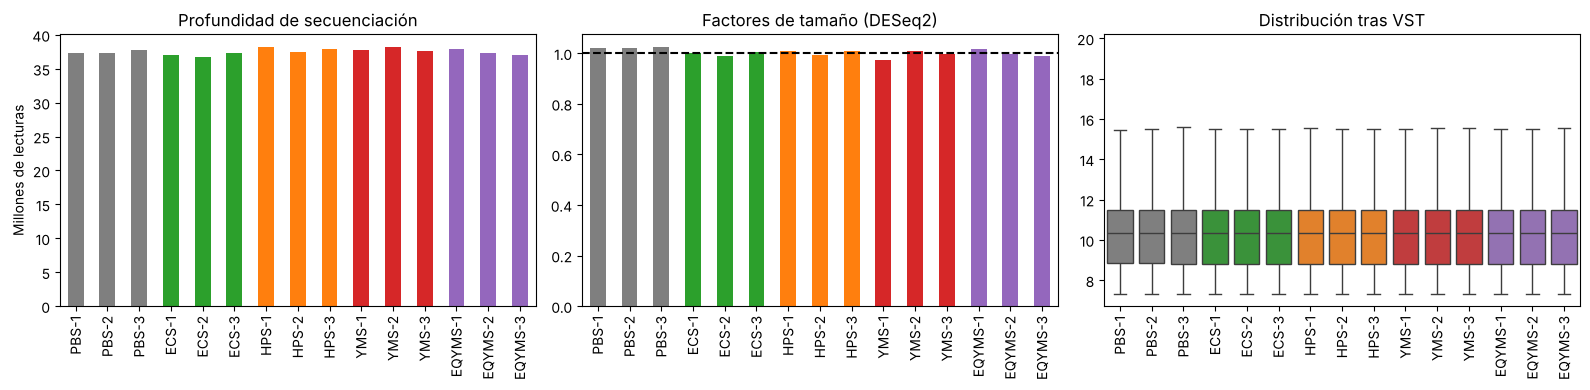

PBS-1      1.019
PBS-2      1.019
PBS-3      1.023
ECS-1      1.002
ECS-2      0.988
ECS-3      1.006
HPS-1      1.008
HPS-2      0.992
HPS-3      1.010
YMS-1      0.974
YMS-2      1.009
YMS-3      0.996
EQYMS-1    1.018
EQYMS-2    0.999
EQYMS-3    0.988


In [9]:
# Acá normalizo los datos con DESeq2 (corrijo la profundidad de secuenciación y paso a
# escala logarítmica) y hago gráficos para comprobar que quedó bien.

inferencia = DefaultInference(n_cpus=2)
# Creo el objeto de DESeq2 con los conteos filtrados (las muestras como filas), el grupo de
# cada muestra y PBS como referencia.
dds = DeseqDataSet(counts=conteos_f.T, metadata=metadatos[['grupo']],
                   design='~grupo', ref_level=['grupo', 'PBS'],
                   inference=inferencia, quiet=True)
# Calcula los factores de tamaño (método de la "mediana de cocientes").
dds.fit_size_factors()
# Aplica la transformación VST. use_design=False significa que no usa los grupos para
# transformar, así no "ayuda" a que los grupos se separen artificialmente.
dds.vst(use_design=False)

factores = pd.Series(dds.obs['size_factors'].values, index=orden_muestras, name='factor_tamaño')
vst = pd.DataFrame(dds.layers['vst_counts'], index=orden_muestras, columns=conteos_f.index).T  # genes x muestras

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
(conteos.sum() / 1e6).plot.bar(ax=ax[0], color=metadatos['color'])
ax[0].set_title('Profundidad de secuenciación'); ax[0].set_ylabel('Millones de lecturas')
factores.plot.bar(ax=ax[1], color=metadatos['color']); ax[1].axhline(1, ls='--', c='k')
ax[1].set_title('Factores de tamaño (DESeq2)')
sns.boxplot(data=vst, ax=ax[2], palette=metadatos['color'].tolist(), fliersize=0)
ax[2].set_title('Distribución tras VST'); ax[2].tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()
print(factores.round(3).to_string())

**¿Qué se observa?** Todas las muestras tienen entre 36,8 y 38,1 millones de lecturas y los factores de tamaño quedan muy cerca de 1 (aprox. 0,97 – 1,03). Es decir, la secuenciación fue pareja y ninguna muestra tiene un problema de profundidad. Después de la VST, las distribuciones de las 15 muestras son prácticamente idénticas, que es lo esperado si la normalización funcionó: lo que distinga a las muestras de acá en adelante será biología (o artefactos puntuales), no profundidad.

## 6. Control de calidad y detección de una contaminación

**Objetivo:** verificar que las réplicas se parecen entre sí y buscar muestras o genes "raros" antes de sacar conclusiones.

**Por qué lo hago:** El análisis exploratorio sirve para buscar outliers y relaciones inesperadas *antes* de modelar. Si hay un artefacto técnico y no lo detecté, cualquier análisis posterior (expresión diferencial, enriquecimiento, ML) lo va a "descubrir" como si fuera biología.

**Método:**
1. Correlación de Pearson entre todas las muestras (sobre la matriz VST) y mapa de calor.
2. Revisión de genes que no deberían expresarse en una línea de macrófagos. Durante la exploración apareció *Pnlip* (lipasa pancreática) con cientos de lecturas en algunas muestras, algo biológicamente imposible en RAW264.7. Para saber si es un gen aislado o un patrón, busqué todos los genes cuya expresión se correlaciona con Pnlip (r > 0,9) a lo largo de las 15 muestras: si es una contaminación con otro tejido, deberían aparecer juntos los genes típicos de ese tejido.
3. Con ese módulo armé un puntaje de contaminación por muestra y busqué qué otros genes lo siguen (r > 0,8), para tener la lista completa de genes "sospechosos".

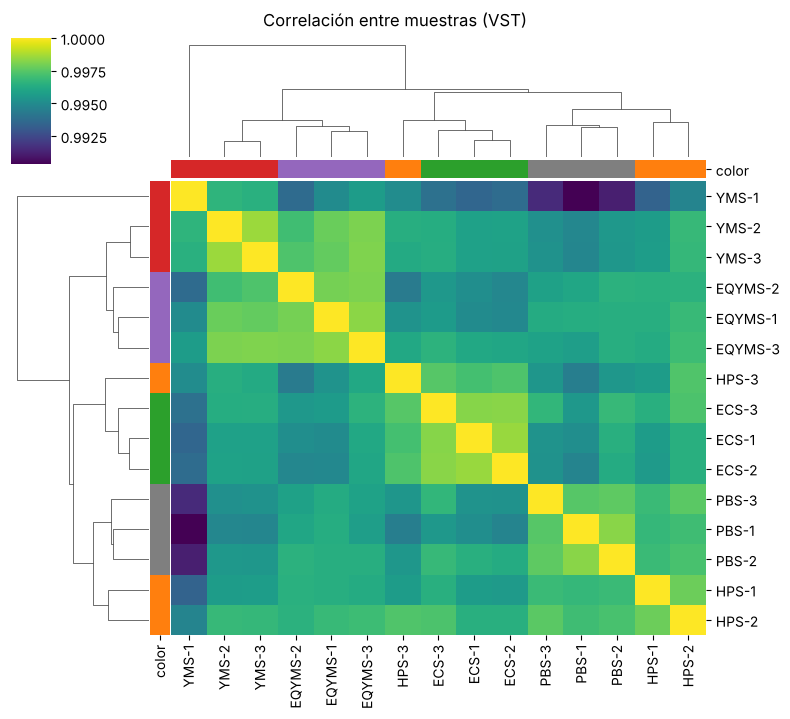

Correlación entre réplicas del mismo grupo: mínimo 0.9956, media 0.9977
Correlación mínima en toda la matriz       : 0.9904


In [10]:
# En esta celda mido cuánto se parecen todas las muestras entre sí y lo muestro en un mapa
# de calor.

# Calcula la correlación de Pearson entre cada par de muestras, usando los 12.868 genes. Da
# una tabla de 15 × 15.
correl = vst.corr(method='pearson')
# Dibuja esa tabla como mapa de calor (colores según el valor) y además reordena las
# muestras poniendo juntas las más parecidas.
g = sns.clustermap(correl, cmap='viridis', figsize=(8, 7), annot=False,
                   # Una franja de color al costado que indica el grupo de cada muestra.
                   row_colors=metadatos['color'], col_colors=metadatos['color'])
g.fig.suptitle('Correlación entre muestras (VST)', y=1.02); plt.show()

# Junta todas las correlaciones entre réplicas del mismo grupo.
intra = [correl.loc[a, b] for gr in orden_grupos for a in metadatos.index[metadatos.grupo == gr]
         for b in metadatos.index[metadatos.grupo == gr] if a < b]
print(f'Correlación entre réplicas del mismo grupo: mínimo {min(intra):.4f}, media {np.mean(intra):.4f}')
print(f'Correlación mínima en toda la matriz       : {correl.values.min():.4f}')

In [11]:
# Acá busco los genes que suben y bajan junto con *Pnlip* (la lipasa pancreática), para
# encontrar el grupo de genes contaminantes.

# Divide cada conteo por el total de su muestra y multiplica por un millón (eso es CPM,
# "conteos por millón"); suma 1 (porque log de 0 no existe) y aplica log₂.
log_cpm = np.log2(conteos_f / conteos_f.sum() * 1e6 + 1)
# Calcula la correlación de cada gen con Pnlip, a lo largo de las 15 muestras.
r_pnlip = log_cpm.T.corrwith(log_cpm.loc['Pnlip'])
# Se queda con los genes con correlación mayor a 0,9, los ordena de mayor a menor
# (sort_values) y guarda sus nombres en una lista.
modulo_pancreatico = r_pnlip[r_pnlip > 0.9].sort_values(ascending=False).index.tolist()

# Toma la descripción de cada gen y arregla un detalle: en el archivo, las comas aparecen
# escritas como %2C.
desc = anot['description'].str.replace('%2C', ',', regex=False)
print(f'Genes correlacionados con Pnlip (r > 0,9): {len(modulo_pancreatico)}')
# Arma una tabla con la correlación y la descripción de cada gen del módulo.
pd.DataFrame({'r con Pnlip': r_pnlip[modulo_pancreatico].round(3),
              'descripción': desc[modulo_pancreatico]})

Genes correlacionados con Pnlip (r > 0,9): 30


,r con Pnlip,descripción
id,,
Pnlip,1.000,pancreatic lipase
Clps,0.996,"colipase, pancreatic"
Prss2,0.993,"protease, serine 2"
Cpb1,0.992,carboxypeptidase B1 (tissue)
2210010C04Rik,0.991,RIKEN cDNA 2210010C04 gene
Cel,0.991,carboxyl ester lipase
Try4,0.990,trypsin 4
Cela2a,0.990,"chymotrypsin-like elastase family, member 2A"
Ctrb1,0.989,chymotrypsinogen B1


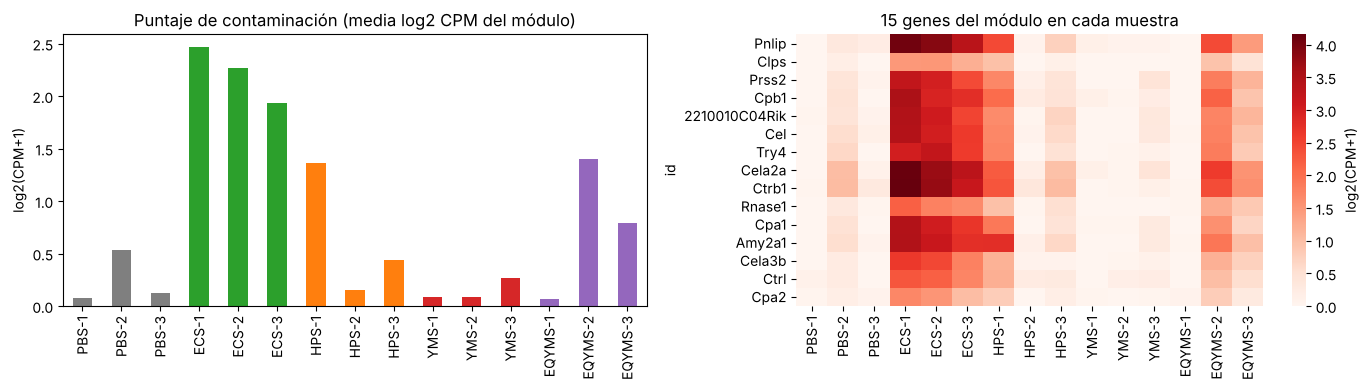

id       Pnlip  Cel  Ctrb1  Cpa1
PBS-1        0    0      1     0
PBS-2        9   18     39    15
PBS-3        6    4      9     0
ECS-1      584  365    623   369
ECS-2      508  264    460   270
ECS-3      343  193    300   204
HPS-1      169   85    152   103
HPS-2        2    2     10     0
HPS-3       25   20     40    14
YMS-1        4    0      0     1
YMS-2        2    0      1     1
YMS-3        2    9      4     8
EQYMS-1      0    1      1     0
EQYMS-2    164   91    161    74
EQYMS-3     64   34     76    22


In [12]:
# En esta celda calculo un "puntaje de contaminación" para cada muestra y lo grafico.

# Toma los 30 genes del módulo y promedia su expresión en cada muestra. Ese promedio es el
# puntaje: más alto quiere decir más contaminación.
puntaje_contam = log_cpm.loc[modulo_pancreatico].mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
# Una barra por muestra con su puntaje.
puntaje_contam.plot.bar(ax=ax[0], color=metadatos['color'])
ax[0].set_title('Puntaje de contaminación (media log2 CPM del módulo)'); ax[0].set_ylabel('log2(CPM+1)')
sns.heatmap(log_cpm.loc[modulo_pancreatico[:15]], cmap='Reds', ax=ax[1], cbar_kws={'label': 'log2(CPM+1)'})
ax[1].set_title('15 genes del módulo en cada muestra')
plt.tight_layout(); plt.show()
print(conteos.loc[['Pnlip', 'Cel', 'Ctrb1', 'Cpa1']].T)

In [13]:
# Acá amplío la búsqueda: encuentro todos los genes que siguen al puntaje de contaminación,
# aunque no sean del páncreas.

# Amplío la búsqueda: genes que siguen el puntaje de contaminación (r > 0,8), aunque no estén en el módulo
# La correlación de cada gen con el puntaje de contaminación.
r_puntaje = log_cpm.T.corrwith(puntaje_contam)
# Los genes con correlación mayor a 0,8. Esta lista de 47 genes se usa en todo el resto del
# notebook.
genes_contaminantes = r_puntaje[r_puntaje > 0.8].index.tolist()
# Los genes nuevos, que no estaban en el módulo pancreático original.
extra = [g for g in genes_contaminantes if g not in modulo_pancreatico]
print(f'Genes contaminantes totales (r > 0,8 con el puntaje): {len(genes_contaminantes)}  → {len(extra)} además del módulo pancreático')
pd.DataFrame({'r con el puntaje': r_puntaje[extra].round(2), 'descripción': desc.reindex(extra),
              'lecturas en ECS-1': conteos.loc[extra, 'ECS-1'], 'lecturas en PBS-1': conteos.loc[extra, 'PBS-1']}
            ).sort_values('r con el puntaje', ascending=False)

Genes contaminantes totales (r > 0,8 con el puntaje): 47  → 17 además del módulo pancreático


,r con el puntaje,descripción,lecturas en ECS-1,lecturas en PBS-1
id,,,,
Alpi,0.90,"alkaline phosphatase, intestinal",37,2
Serpina1c,0.90,"serine (or cysteine) peptidase inhibitor, clad...",41,3
Plac8,0.89,placenta-specific 8,14,0
Reg3g,0.89,regenerating islet-derived 3 gamma,40,0
Pnliprp2,0.87,pancreatic lipase-related protein 2,42,0
Defa24,0.87,"defensin, alpha, 24",26,0
Clu,0.86,clusterin,563,436
Bhmt,0.86,betaine-homocysteine methyltransferase,22,4
Muc3,0.85,"mucin 3, intestinal",19,0


**¿Qué se observa?**
- Las réplicas son muy reproducibles (correlación ≥ 0,995 entre réplicas del mismo grupo). Pero también todas las muestras se parecen muchísimo entre sí (la correlación más baja de toda la matriz es 0,990). Esto anticipa que los tratamientos producen efectos sutiles sobre el transcriptoma, no una reprogramación masiva. En el clustering de la matriz de correlación, las réplicas de miricetina y de dihidromiricetina se agrupan bien, y llama la atención que HPS-3 (quercetina) queda junto a las de catequina y no con las otras dos réplicas de quercetina.
- Detecté una contaminación. El análisis de correlación encontró un módulo de 30 genes que suben y bajan juntos con *Pnlip*, y prácticamente todos son enzimas digestivas del páncreas exocrino (lipasa pancreática, colipasa, tripsinas, quimotripsinas, carboxipeptidasas, elastasas, amilasa, RNasa pancreática, proteínas de gránulos de zimógeno) más algunos marcadores intestinales (*Apoa4*, *Akp3*, *Muc13*). Al ampliar la búsqueda aparecen además genes de hígado (*Aldob, Apob, Bhmt, Gnmt, Serpina1c, Cyp3a13*) e intestino (*Alpi, Krt20, Muc3, Slc5a1, Defa24*). Un macrófago en cultivo no fabrica estas proteínas: lo más probable es que haya ARN de tejido digestivo en las muestras.
- El puntaje de contaminación es máximo en las tres réplicas de catequina (ECS), intermedio en algunas muestras de otros grupos (EQYMS-2, HPS-1, EQYMS-3) y casi nulo en otras (PBS-1, YMS-1, YMS-2, EQYMS-1). Que aparezca en grupos distintos y con intensidad variable sugiere un artefacto técnico de manipulación y no un efecto del flavonoide (no hay mecanismo por el cual la catequina haga que un macrófago exprese tripsina). Lo importante es la consecuencia: justo en el grupo que el paper analizó (catequina) la contaminación es máxima.

Por eso decidí no eliminar muestras (me quedaría sin réplicas), pero sí marcar estos 47 genes como contaminantes: los voy a señalar en la expresión diferencial y los voy a excluir del PCA, del análisis funcional y del machine learning. Es una decisión conservadora: quizás alguno de los 47 (por ejemplo *Clu*) sí se exprese en macrófagos, pero perder unos pocos genes de 12.868 no cambia nada, mientras que dejarlos puede crear "resultados" falsos.

## 7. Reducción de dimensionalidad: PCA

**Objetivo:** ver en un solo gráfico cómo se ordenan las 15 muestras usando la información de miles de genes a la vez.

**Por qué lo hago:** Cada muestra es un punto en un espacio de ~12.000 dimensiones (un eje por gen): imposible de mirar. El Análisis de Componentes Principales (PCA) busca nuevas direcciones (componentes principales) que maximizan la varianza de las proyecciones, lo que equivale a minimizar el error de reconstrucción. Cada PC es una combinación lineal de todos los genes; PC1 captura la mayor diferencia entre muestras, PC2 la siguiente que PC1 no explica (es ortogonal), y así sucesivamente. Las direcciones de mayor varianza concentran la señal y las de menor varianza suelen ser ruido. Si los tratamientos tienen efecto, las réplicas deberían agruparse y separarse de otros grupos.

**Método:** usé los 500 genes más variables de la matriz VST (los que tienen algo para mostrar; un gen con varianza ≈ 0 no ayuda a distinguir muestras). Hice el PCA dos veces: con todos los genes y sin el módulo contaminante, para ver cuánto de la estructura se debe al artefacto. Igual que en la práctica de PCA, reporté la tabla de varianza explicada, el gráfico de varianza acumulada y los *loadings* (cuánto pesa cada gen en cada PC).

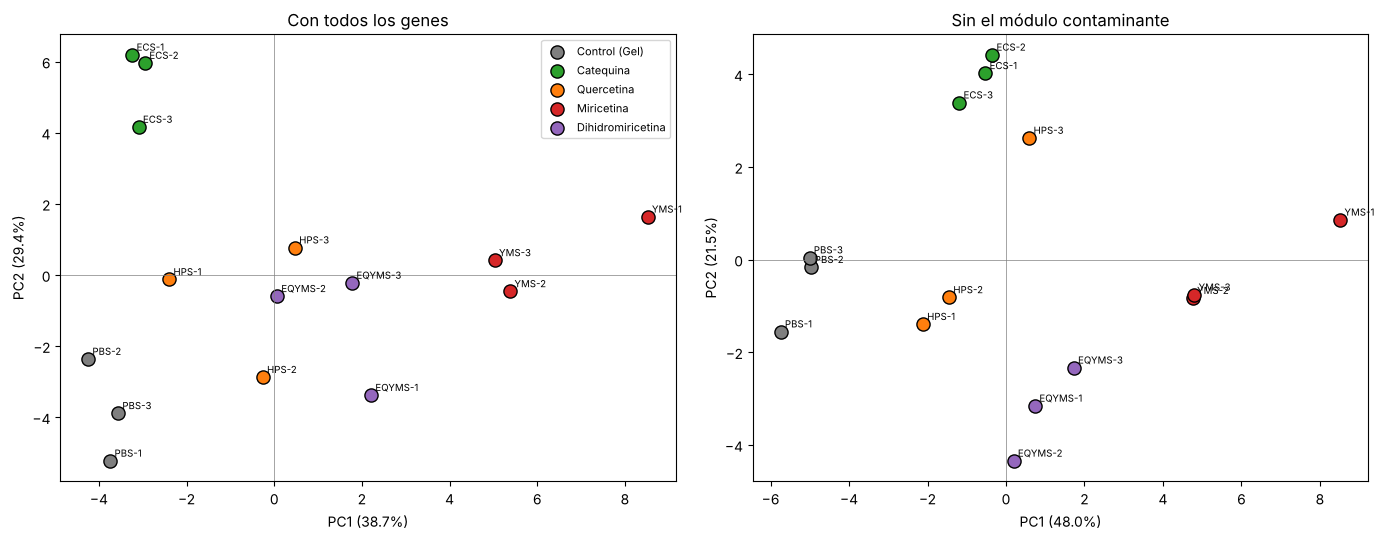

In [14]:
# En esta celda hago el PCA y grafico las 15 muestras en dos dimensiones, con y sin los
# genes contaminantes.

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def hacer_pca(matriz_genes_x_muestras, n_top=500):
    # Calcula la varianza de cada gen (cuánto cambia entre muestras) y los ordena de mayor a
    # menor.
    var = matriz_genes_x_muestras.var(axis=1).sort_values(ascending=False)
    top = var.index[:n_top]
    # La tabla con esos 500 genes, dada vuelta: muestras como filas.
    X = matriz_genes_x_muestras.loc[top].T          # muestras x genes
    Xc = X - X.mean()                               # centrado (los genes ya están en la misma escala log)
    # Calcula el PCA y las coordenadas de cada muestra en los nuevos ejes.
    pca = PCA()
    coords = pca.fit_transform(Xc)
    return pca, pd.DataFrame(coords[:, :5], index=X.index, columns=[f'PC{i}' for i in range(1, 6)]), top

# La tabla VST sin los 47 contaminantes.
vst_limpio = vst.drop(index=genes_contaminantes)
# PCA con todos los genes. El _ quiere decir "esto no lo voy a usar".
pca_todo, coord_todo, _ = hacer_pca(vst)
pca_limpio, coord_limpio, top_limpio = hacer_pca(vst_limpio)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, (p, cd, titulo) in zip(ax, [(pca_todo, coord_todo, 'Con todos los genes'),
                                   (pca_limpio, coord_limpio, 'Sin el módulo contaminante')]):
    for gr in orden_grupos:
        s = metadatos.index[metadatos.grupo == gr]
        a.scatter(cd.loc[s, 'PC1'], cd.loc[s, 'PC2'], c=colores[gr], s=90, label=nombres[gr], edgecolor='k')
        for m in s: a.annotate(m, (cd.loc[m, 'PC1'], cd.loc[m, 'PC2']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    a.set_xlabel(f'PC1 ({p.explained_variance_ratio_[0]:.1%})'); a.set_ylabel(f'PC2 ({p.explained_variance_ratio_[1]:.1%})')
    a.set_title(titulo); a.axhline(0, c='grey', lw=.5); a.axvline(0, c='grey', lw=.5)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

     desvío_estándar  proporción_varianza  proporción_acumulada
PC1            3.904                0.480                 0.480
PC2            2.610                0.215                 0.695
PC3            1.515                0.072                 0.767
PC4            1.106                0.039                 0.806
PC5            1.056                0.035                 0.841
PC6            0.955                0.029                 0.869


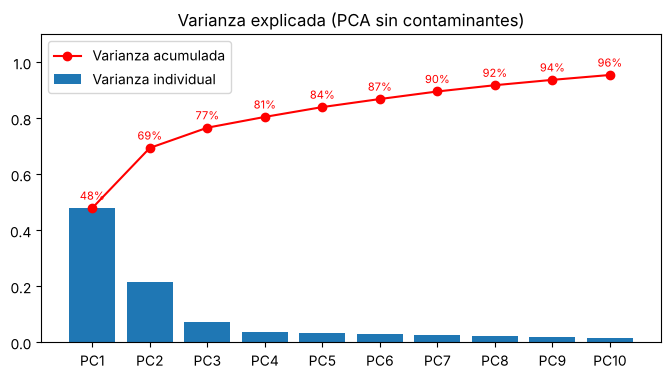


PC1 - genes con mayor carga negativa: Mki67, Kif20b, Mettl1, Thoc2, Cenpf, Smc4, Ppig, Cenpe
PC1 - genes con mayor carga positiva: Hmox1, Gclm, Ptpn14, LOC118568312, Procr, Blvrb, Lars2, Srxn1

PC2 - genes con mayor carga negativa: Tigd2, Serpinb9b, P2ry10b, Zfp62, Prdx1, Arhgap5, Gpbp1, Creg1
PC2 - genes con mayor carga positiva: Entpd4b, Lars2, Mettl1, LOC118568312, Alb, Med22, Nos2, Ppfia4


In [15]:
# Acá veo cuánta información guarda cada componente del PCA y qué genes "mueven" cada eje.

# Una tabla con tres columnas por componente: el desvío estándar, la proporción de varianza
# que explica y la proporción acumulada (sumando las anteriores).
resumen_pca = pd.DataFrame({
    'desvío_estándar': np.sqrt(pca_limpio.explained_variance_),
    'proporción_varianza': pca_limpio.explained_variance_ratio_,
    'proporción_acumulada': np.cumsum(pca_limpio.explained_variance_ratio_)},
    index=[f'PC{i}' for i in range(1, len(pca_limpio.explained_variance_) + 1)])
print(resumen_pca.head(6).round(3))

var = pca_limpio.explained_variance_ratio_[:10]; acum = np.cumsum(var); pcs = np.arange(1, 11)
plt.figure(figsize=(8, 4))
plt.bar(pcs, var, label='Varianza individual'); plt.plot(pcs, acum, 'o-', c='red', label='Varianza acumulada')
for pc, a_ in zip(pcs, acum): plt.text(pc, a_ + .03, f'{a_:.0%}', ha='center', color='red', fontsize=8)
plt.xticks(pcs, [f'PC{i}' for i in pcs]); plt.ylim(0, 1.1); plt.legend(); plt.title('Varianza explicada (PCA sin contaminantes)')
plt.show()

# Las cargas (loadings): cuánto pesa cada gen en PC1 y en PC2. Un gen con carga grande
# "empuja" mucho a las muestras en ese eje.
cargas = pd.DataFrame(pca_limpio.components_[:2].T, index=top_limpio, columns=['PC1', 'PC2'])
for pc in ['PC1', 'PC2']:
    orden = cargas[pc].sort_values()
    print(f'\n{pc} - genes con mayor carga negativa:', ', '.join(orden.index[:8]))
    print(f'{pc} - genes con mayor carga positiva:', ', '.join(orden.index[-8:][::-1]))

**¿Qué se observa?**
- Con todos los genes, PC2 (29 %) separa a las tres réplicas de catequina del resto, en parte empujadas por los genes contaminantes, que son de los más variables del dataset.
- Sin los genes contaminantes, PC1 + PC2 explican cerca del 70 % de la varianza y la estructura se vuelve más clara:
  - PC1 (48 %) ordena las muestras desde el control (izquierda) hasta la miricetina (derecha), con quercetina y dihidromiricetina en el medio. Los genes con mayor carga positiva son Hmox1, Gclm, Srxn1, Blvrb, Procr (respuesta antioxidante tipo Nrf2 y metabolismo del hemo), y los de carga negativa son Mki67, Kif20b, Cenpf, Cenpe, Smc4 (proliferación celular). Es decir, PC1 es un eje "defensa antioxidante ↑ / proliferación ↓".
  - PC2 (22 %) separa a la catequina (arriba) de la dihidromiricetina (abajo). O sea que, aun sin el artefacto, la catequina tiene su propia firma, distinta de la de los otros flavonoides y que no pasa por el eje antioxidante (en PC1 queda cerca del control).
- La réplica HPS-3 de quercetina vuelve a aparecer cerca de catequina y lejos de HPS-1 y HPS-2: es una réplica atípica que voy a tener en cuenta.

Esto es una primera evidencia a favor de H1: el gradiente principal del transcriptoma, una vez quitado el artefacto, es un gradiente de respuesta antioxidante, en el que la catequina queda del lado del control.

## 8. Agrupamiento (clustering) de muestras

**Objetivo:** preguntarle a los datos, sin darles las etiquetas, qué muestras se parecen, y comparar esos grupos "naturales" con los tratamientos reales.

**Por qué lo hago:** El clustering es aprendizaje no supervisado: agrupa objetos de modo que los de un mismo grupo sean más parecidos entre sí que con los de otros grupos, usando una medida de distancia. Si el tratamiento define realmente el perfil transcriptómico, los clusters deberían coincidir con los grupos experimentales; si no coinciden, me dice que algunos tratamientos son indistinguibles. Usé los dos tipos de métodos:
- Jerárquico aglomerativo: empieza con cada muestra como su propio cluster y va fusionando los más similares; el resultado es un dendrograma. Comparé los tres criterios de enlace: *single* (distancia mínima, tiende a formar cadenas), *complete* (distancia máxima, clusters compactos) y *average* (promedio, compromiso entre ambos).
- K-means (divisivo): parte el espacio en K grupos asignando cada punto al centroide más cercano. Su desventaja es que hay que fijar K de antemano y depende de la inicialización; por eso usé K = 5 (los grupos del diseño) y varias inicializaciones (`n_init`).

**Método:** usé la matriz sin contaminantes y las coordenadas de las primeras 5 PCs (resumen sin ruido). Para cuantificar la coincidencia con los grupos reales usé el índice de Rand ajustado (ARI): 1 = coincidencia perfecta, 0 = lo esperable por azar.

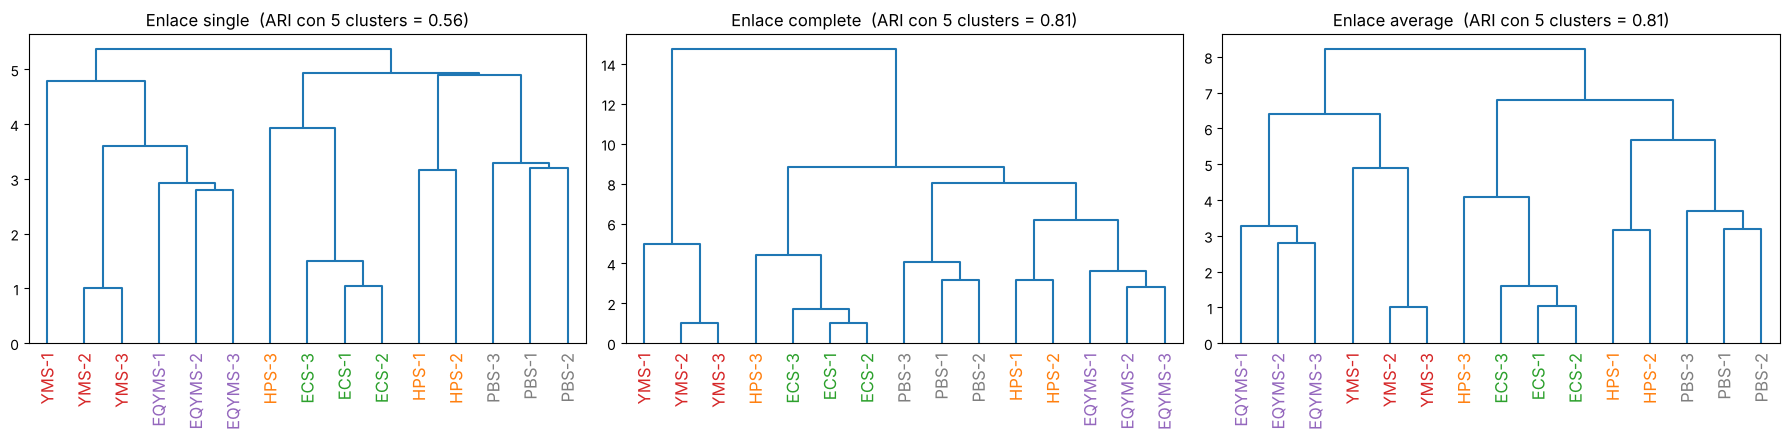

K-means (K=5): ARI = 0.81


Cluster K-means,0,1,2,3,4
Tratamiento real,,,,,
Catequina,3,0,0,0,0
Control (Gel),0,0,3,0,0
Dihidromiricetina,0,0,0,3,0
Miricetina,0,3,0,0,0
Quercetina,1,0,0,0,2


In [16]:
# En esta celda agrupo las muestras sin decirle a la computadora a qué tratamiento
# pertenecen, y mido si los grupos que arma coinciden con los reales.

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Las coordenadas de las muestras en las 5 primeras componentes.
X_clust = coord_limpio[['PC1', 'PC2', 'PC3', 'PC4', 'PC5']]
etiquetas_reales = metadatos['grupo']

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, metodo in zip(ax, ['single', 'complete', 'average']):
    # Arma el árbol jerárquico usando la distancia euclídea (la distancia "en línea recta").
    Z = linkage(X_clust, method=metodo, metric='euclidean')
    dendrogram(Z, labels=X_clust.index.tolist(), ax=a, leaf_rotation=90, color_threshold=0)
    for t in a.get_xticklabels(): t.set_color(colores[t.get_text().split('-')[0]])
    # Corta el árbol para quedarse con 5 grupos.
    ari = adjusted_rand_score(etiquetas_reales, fcluster(Z, 5, criterion='maxclust'))
    a.set_title(f'Enlace {metodo}  (ARI con 5 clusters = {ari:.2f})')
plt.tight_layout(); plt.show()

# K-means con 5 grupos.
km = KMeans(n_clusters=5, n_init=50, random_state=SEMILLA).fit(X_clust)
tabla_km = pd.crosstab(etiquetas_reales.map(nombres), km.labels_, rownames=['Tratamiento real'], colnames=['Cluster K-means'])
print(f'K-means (K=5): ARI = {adjusted_rand_score(etiquetas_reales, km.labels_):.2f}')
tabla_km

**¿Qué se observa?**
- Las teorías de cada criterio de enlace se cumplen en la práctica. El enlace *single* produce el típico "encadenamiento" (YMS-1 y HPS-3 se suman de a uno a grupos grandes) y es el que peor reconstruye el diseño (ARI = 0,56). *Complete* y *average* forman grupos compactos y coinciden mucho mejor con los tratamientos (ARI = 0,81).
- Con *average*, los grupos naturales son: {dihidromiricetina}, {miricetina} (estas dos ramas se unen entre sí, lo que tiene sentido porque son moléculas emparentadas), {catequina + HPS-3} y {control + HPS-1 + HPS-2}.
- K-means (K = 5) recupera perfectamente catequina, control, miricetina y dihidromiricetina; el único error es la réplica HPS-3, que cae con catequina. Por eso ARI = 0,81 y no 1.

Interpretación: sin darle ninguna etiqueta, el algoritmo reconoce casi todos los tratamientos, así que cada flavonoide deja una huella reproducible. Los dos que más se parecen entre sí son miricetina y dihidromiricetina, y la quercetina es el tratamiento menos homogéneo: dos réplicas quedan cerca del control y una (HPS-3) cerca de la catequina. La expresión diferencial me va a decir qué genes explican estas diferencias.

## 9. Expresión diferencial (DESeq2)

**Objetivo:** identificar, para cada flavonoide, qué genes cambian su expresión respecto del control de forma estadísticamente confiable.

**Por qué lo hago:** El análisis de expresión diferencial es el paso central de la transcriptómica: compara condiciones gen por gen. Elegí DESeq2 porque (1) es el método que usaron los autores, así que la comparación es justa; (2) modela los conteos con una distribución binomial negativa, adecuada para datos de conteo con sobredispersión; y (3) con solo 3 réplicas, "comparte información" entre genes para estimar mejor la dispersión de cada uno.

Un punto crítico es la corrección por comparaciones múltiples: probé ~12.800 genes a la vez. Con p < 0,05 sin corregir, se esperarían ~640 falsos positivos solo por azar. Por eso usé el p ajustado de Benjamini-Hochberg (FDR).

**Método:** modelo `~ grupo` con el control (PBS) como referencia; cuatro contrastes (cada flavonoide vs. control). Criterio principal de significancia: padj < 0,05. Para "cambios grandes" agregué |log2FC| > 1 (el doble o la mitad). Al lado reporté también el criterio del paper (p sin corregir < 0,05 y |log2FC| > 1) para poder comparar.

In [17]:
# Acá corro la expresión diferencial: para cada flavonoide comparo cada gen contra el
# control y cuento cuántos cambian.

# Hace todo el ajuste estadístico.
dds.deseq2()   # ajusta dispersiones y el modelo lineal generalizado

resultados = {}
for t in ['ECS', 'HPS', 'YMS', 'EQYMS']:
    # Define la comparación: "en la variable grupo, comparar t contra PBS".
    st = DeseqStats(dds, contrast=['grupo', t, 'PBS'], inference=inferencia, quiet=True)
    # Calcula el log2FC, el p-valor y el p-valor ajustado (padj) de cada gen.
    st.summary()
    r = st.results_df.copy()
    # Agrega una columna Verdadero/Falso: ¿este gen es contaminante?
    r['contaminante'] = r.index.isin(genes_contaminantes)
    resultados[t] = r

filas = []
for t, r in resultados.items():
    # Genes significativos (padj < 0,05) y, de esos, los que cambian mucho (|log2FC| > 1).
    fdr = r[r.padj < 0.05]; grande = fdr[fdr.log2FoldChange.abs() > 1]
    paper = r[(r.pvalue < 0.05) & (r.log2FoldChange.abs() > 1)]
    filas.append({'Tratamiento': nombres[t],
                  'padj<0,05': len(fdr), '↑': (fdr.log2FoldChange > 0).sum(), '↓': (fdr.log2FoldChange < 0).sum(),
                  'padj<0,05 y |log2FC|>1': len(grande),
                  '…de ellos contaminantes': int(grande.contaminante.sum()),
                  'Criterio del paper (p<0,05, |log2FC|>1)': len(paper),
                  '…de ellos contaminantes ': int(paper.contaminante.sum())})
resumen_de = pd.DataFrame(filas).set_index('Tratamiento')
resumen_de

,"padj<0,05",↑,↓,"padj<0,05 y |log2FC|>1",…de ellos contaminantes,"Criterio del paper (p<0,05, |log2FC|>1)",…de ellos contaminantes
Tratamiento,,,,,,,
Catequina,1473,422,1051,13,10,98,32
Quercetina,808,446,362,3,0,73,3
Miricetina,3559,1720,1839,88,0,187,3
Dihidromiricetina,1660,903,757,31,1,116,4


**Cómo se lee un volcano plot:**

- Eje horizontal (x): el log2FC. A la derecha están los genes que suben, a la izquierda los que bajan.
- Eje vertical (y): −log10(padj). **Cuanto más arriba, más significativo.** (Se usa el menos logaritmo para que los p-valores chiquitos queden arriba.)
- Los genes importantes están arriba y a los costados: la forma del gráfico parece un volcán en erupción.

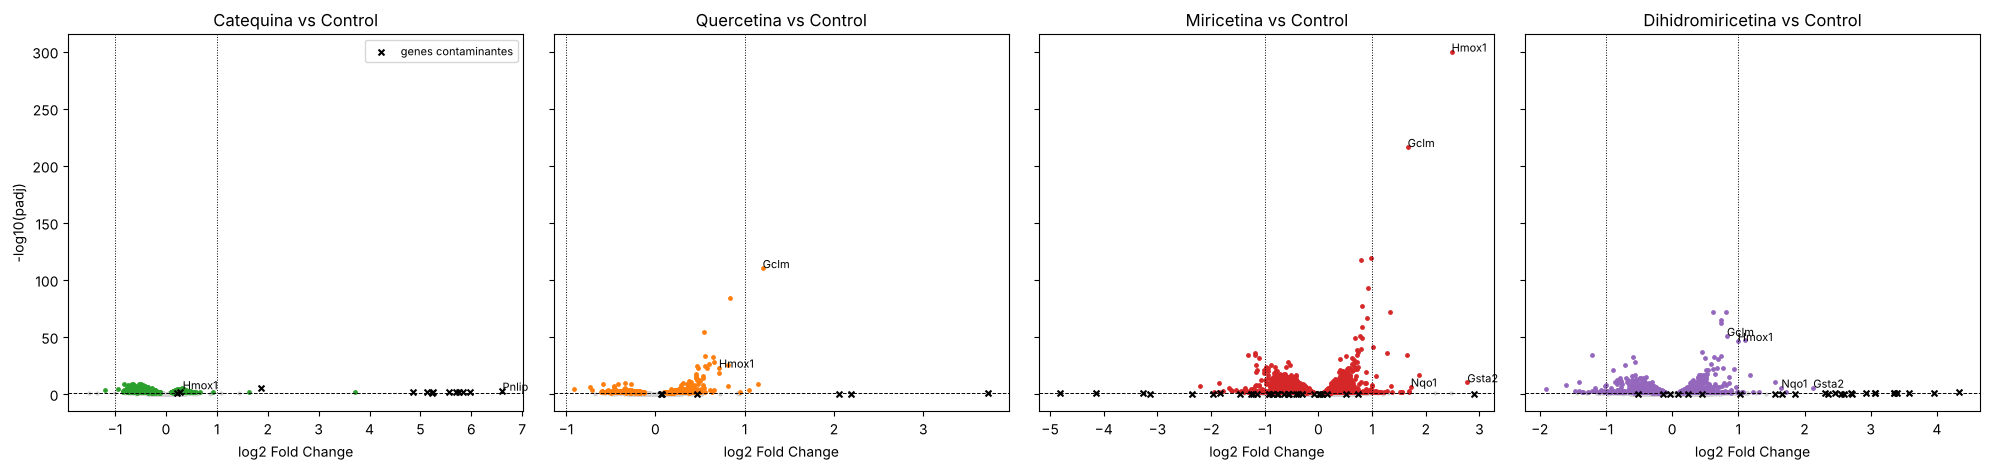

In [18]:
# En esta celda dibujo un volcano plot para cada flavonoide.

fig, ax = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True)
for a, t in zip(ax, ['ECS', 'HPS', 'YMS', 'EQYMS']):
    # Saca los genes sin padj (DESeq2 descarta algunos por baja expresión o valores
    # atípicos).
    r = resultados[t].dropna(subset=['padj'])
    # Calcula el eje y. El clip evita que un padj exactamente 0 dé infinito.
    y = -np.log10(r.padj.clip(lower=1e-300))
    # Cuáles son significativos.
    sig = (r.padj < 0.05)
    # Tres scatter: los no significativos en gris, los significativos con el color del
    # tratamiento, y los contaminantes con una cruz negra.
    a.scatter(r.log2FoldChange[~sig], y[~sig], s=4, c='lightgrey')
    a.scatter(r.log2FoldChange[sig & ~r.contaminante], y[sig & ~r.contaminante], s=6, c=colores[t])
    a.scatter(r.log2FoldChange[r.contaminante], y[r.contaminante], s=18, c='black', marker='x', label='genes contaminantes')
    for gen in ['Hmox1', 'Nqo1', 'Gclm', 'Gsta2', 'Pnlip']:
        if gen in r.index and r.loc[gen, 'padj'] < 0.05:
            a.annotate(gen, (r.loc[gen, 'log2FoldChange'], y[gen]), fontsize=8)
    a.axhline(-np.log10(0.05), ls='--', c='k', lw=.7); a.axvline(-1, ls=':', c='k', lw=.7); a.axvline(1, ls=':', c='k', lw=.7)
    a.set_title(f'{nombres[t]} vs Control'); a.set_xlabel('log2 Fold Change')
ax[0].set_ylabel('-log10(padj)'); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [19]:
# Acá muestro los 10 genes más significativos de cada flavonoide, sin contar los
# contaminantes.

for t in ['ECS', 'HPS', 'YMS', 'EQYMS']:
    r = resultados[t]
    # Los genes significativos que no son contaminantes. El & es "y", y el ~ es "no".
    top = r[(r.padj < 0.05) & ~r.contaminante].sort_values('padj').head(10)
    print(f'\n=== {nombres[t]}: 10 genes más significativos (sin contaminantes) ===')
    print(top[['baseMean', 'log2FoldChange', 'padj']].round(4).to_string())


=== Catequina: 10 genes más significativos (sin contaminantes) ===
            baseMean  log2FoldChange  padj
id                                        
Sltm       2276.6606         -0.4980   0.0
Thoc2      1588.5350         -0.6407   0.0
Septin7    7119.3270         -0.5367   0.0
Cenpf      2764.1350         -0.6594   0.0
Cep290      550.9068         -0.8281   0.0
Haus3       585.8479         -0.7384   0.0
Tpr        7156.3986         -0.4461   0.0
Kif20b     1643.3939         -0.6802   0.0
Ddx3y       643.3067         -0.6312   0.0
Mphosph10  1899.0118         -0.6255   0.0

=== Quercetina: 10 genes más significativos (sin contaminantes) ===
           baseMean  log2FoldChange  padj
id                                       
Gclm      4922.4913          1.2016   0.0
Srxn1     8114.9341          0.8303   0.0
Txnrd1   25036.2579          0.5412   0.0
Creg1    15642.4881          0.5577   0.0
Cat       8074.0758          0.6452   0.0
Akr1b8    9101.1493          0.6532   0.0
Ftl1    518

**¿Qué se observa?**
- Catequina: tiene muchos genes con padj < 0,05 (la mayoría bajan), pero con cambios pequeños. De los pocos genes con cambio grande (padj < 0,05 y |log2FC| > 1), casi todos son contaminantes (cruces negras en el volcán). Con el criterio permisivo del paper, una buena parte de sus "genes diferenciales" también son enzimas digestivas. Entre los genes más significativos que no son contaminantes aparecen genes de proliferación y procesamiento de ARN que bajan levemente (*Kif20b, Cenpf, Cep290, Thoc2*): la catequina sí hace algo, pero de baja magnitud.
- Miricetina es el tratamiento con más genes diferenciales y con los cambios más grandes. Su gen más significativo es Hmox1 (log2FC ≈ 2,5, es decir, unas 5,6 veces más expresado), seguido por Gclm, Srxn1, Txnrd1, Cat (catalasa) y *Pgd*, todos genes de defensa antioxidante, mientras que bajan genes de proliferación (*Mki67*, *Kif20b*).
- Quercetina y dihidromiricetina tienen en su top los mismos genes antioxidantes (*Gclm, Srxn1, Txnrd1, Cat, Gsr, Blvrb*), con efectos intermedios.
- Algunos genes tienen padj = NaN: DESeq2 los descarta del ajuste (filtrado independiente por baja expresión o valores atípicos según la distancia de Cook). Es un comportamiento esperado del método, no un error.

Esto apoya **H1**: hay una respuesta antioxidante compartida en tres de los cuatro flavonoides, y la catequina es la que menos la produce.

## 10. Comparación entre los cuatro flavonoides

**Objetivo:** responder la pregunta central: ¿la respuesta es compartida o específica de cada flavonoide?

**Por qué lo hago:** Una lista de genes por tratamiento no alcanza: hay que ver cuánto se superponen y si los efectos van en la misma dirección. Si dos tratamientos activan el mismo programa, sus log2FC deberían estar correlacionados en todo el genoma. Además, en lugar de mirar genes sueltos, conviene resumir un programa biológico conocido (Nrf2) en un puntaje por muestra, que es más robusto que cualquier gen individual.

**Método:**
1. Superposición de genes diferenciales (padj < 0,05) entre tratamientos.
2. Correlación de los log2FC de todos los genes entre pares de tratamientos.
3. Puntaje Nrf2: promedio de la expresión estandarizada (z-score) de genes blanco clásicos de Nrf2.
4. Mapa de calor de los genes diferenciales con clustering jerárquico de genes (agrupa genes con el mismo patrón de respuesta).

Combinaciones más frecuentes de tratamientos que comparten genes diferenciales:
 Catequina  Quercetina  Miricetina  Dihidromiricetina  n_genes
     False       False        True              False     1395
     False       False        True               True      866
      True       False        True              False      521
      True       False       False              False      400
     False       False       False               True      283
      True       False        True               True      179
     False        True       False              False      155
     False        True        True               True      154
     False        True        True              False      152
      True        True        True              False      148

Genes diferenciales en los 4 tratamientos a la vez: 144
Genes diferenciales en quercetina + miricetina + dihidromiricetina: 298


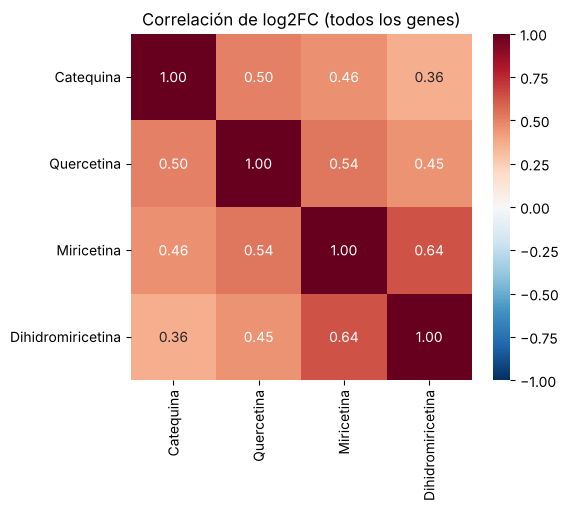

In [20]:
# En esta celda comparo los flavonoides entre sí: cuántos genes comparten y si cambian en la
# misma dirección.

# Para cada tratamiento, el conjunto de genes significativos (sin contaminantes).
sig_sets = {t: set(r[(r.padj < 0.05) & ~r.contaminante].index) for t, r in resultados.items()}
# La unión: todos los genes que son significativos en al menos un tratamiento.
todos = set.union(*sig_sets.values())
# Una tabla con un gen por fila y una columna por tratamiento, con Verdadero si el gen es
# significativo en ese tratamiento.
patron = pd.DataFrame({nombres[t]: [g in s for g in todos] for t, s in sig_sets.items()}, index=list(todos))
# Cuenta cuántos genes tienen cada combinación (por ejemplo, "significativo en miricetina y
# quercetina, pero no en los otros").
conteo_patrones = patron.value_counts().reset_index(name='n_genes').sort_values('n_genes', ascending=False).head(10)
print('Combinaciones más frecuentes de tratamientos que comparten genes diferenciales:')
print(conteo_patrones.to_string(index=False))
print(f"\nGenes diferenciales en los 4 tratamientos a la vez: {patron.all(axis=1).sum()}")
print(f"Genes diferenciales en quercetina + miricetina + dihidromiricetina: {patron[['Quercetina','Miricetina','Dihidromiricetina']].all(axis=1).sum()}")

# Una tabla con el log2FC de cada gen en cada tratamiento.
lfc = pd.DataFrame({nombres[t]: r.log2FoldChange for t, r in resultados.items()}).drop(index=genes_contaminantes)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(lfc.corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Correlación de log2FC (todos los genes)'); plt.show()

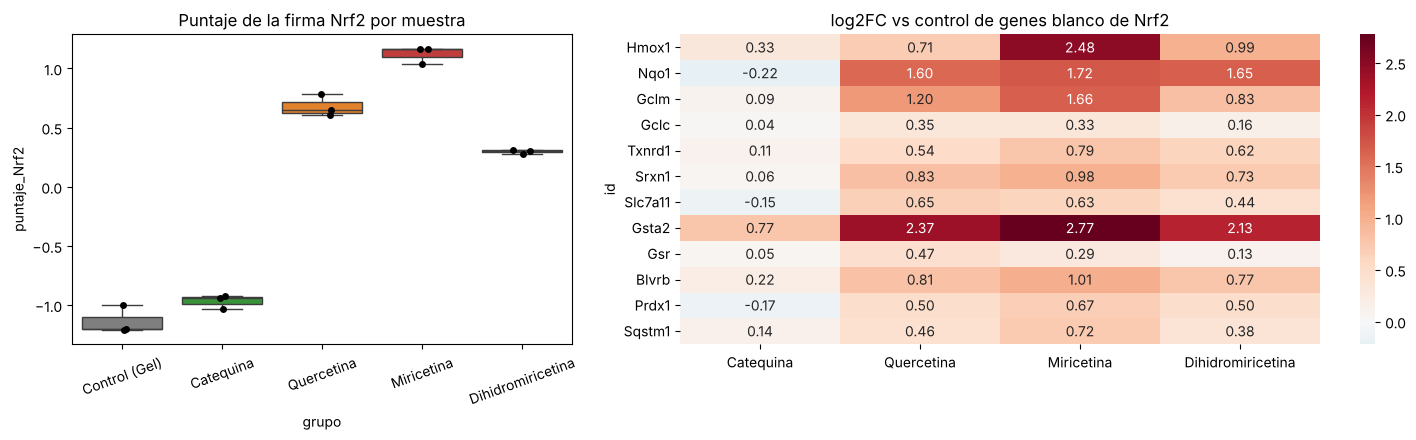

ANOVA de un factor del puntaje Nrf2 entre los 5 grupos: F = 492.0, p = 1.97e-11
grupo
PBS     -1.14
ECS     -0.97
HPS      0.68
YMS      1.12
EQYMS    0.30
Name: puntaje_Nrf2, dtype: float64


In [21]:
# Acá calculo el puntaje Nrf2 de cada muestra y pruebo con un ANOVA si cambia entre grupos.

# La lista de genes blanco de Nrf2.
genes_nrf2 = ['Hmox1', 'Nqo1', 'Gclm', 'Gclc', 'Txnrd1', 'Srxn1', 'Slc7a11', 'Gsta2', 'Gsr', 'Blvrb', 'Prdx1', 'Sqstm1']
# Me quedo solo con los que pasaron el filtro (por si alguno no está).
genes_nrf2 = [g for g in genes_nrf2 if g in vst.index]
# El z-score: a cada gen le resto su promedio y lo divido por su desvío.
z = vst.loc[genes_nrf2].sub(vst.loc[genes_nrf2].mean(axis=1), axis=0).div(vst.loc[genes_nrf2].std(axis=1), axis=0)
# El promedio de los 12 z-scores en cada muestra, guardado como nueva columna.
metadatos['puntaje_Nrf2'] = z.mean()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})
sns.boxplot(data=metadatos, x='grupo', y='puntaje_Nrf2', order=orden_grupos, palette=colores, ax=ax[0])
sns.stripplot(data=metadatos, x='grupo', y='puntaje_Nrf2', order=orden_grupos, color='k', ax=ax[0])
ax[0].set_xticklabels([nombres[g] for g in orden_grupos], rotation=20); ax[0].set_title('Puntaje de la firma Nrf2 por muestra')
sns.heatmap(lfc.reindex(genes_nrf2), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[1])
ax[1].set_title('log2FC vs control de genes blanco de Nrf2')
plt.tight_layout(); plt.show()

# El ANOVA de un factor: prueba si el promedio del puntaje es igual en los 5 grupos o si al
# menos uno es distinto.
anova = stats.f_oneway(*[metadatos.loc[metadatos.grupo == g, 'puntaje_Nrf2'] for g in orden_grupos])
print(f'ANOVA de un factor del puntaje Nrf2 entre los 5 grupos: F = {anova.statistic:.1f}, p = {anova.pvalue:.2e}')
print(metadatos.groupby('grupo')['puntaje_Nrf2'].mean().reindex(orden_grupos).round(2))

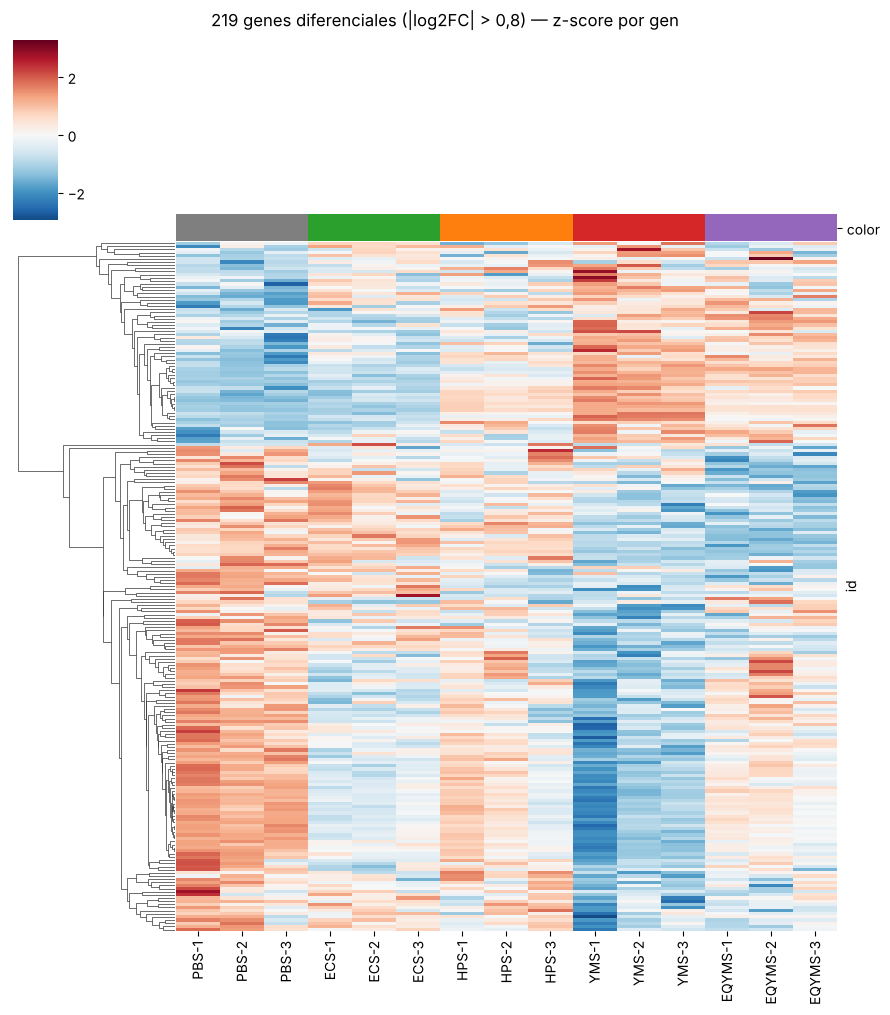

In [22]:
# En esta celda dibujo un mapa de calor con los genes que más cambian, agrupando los que se
# comportan parecido.

# Junta los genes significativos con |log2FC| > 0,8 en cualquier tratamiento (sin
# contaminantes).
genes_heat = sorted(set.union(*[set(r[(r.padj < 0.05) & ~r.contaminante & (r.log2FoldChange.abs() > 0.8)].index)
                                for r in resultados.values()]))
# Sus valores VST.
mat = vst.loc[genes_heat]
# Z-score por gen, para que el color muestre "alto o bajo para ese gen" y no la expresión
# absoluta.
mat_z = mat.sub(mat.mean(axis=1), axis=0).div(mat.std(axis=1), axis=0)
# Mapa de calor que agrupa los genes parecidos (filas) pero deja las muestras en su orden
# original (col_cluster=False).
g = sns.clustermap(mat_z, method='average', metric='correlation', col_cluster=False, cmap='RdBu_r', center=0,
                   col_colors=metadatos['color'], figsize=(9, 10), yticklabels=len(genes_heat) <= 70)
g.fig.suptitle(f'{len(genes_heat)} genes diferenciales (|log2FC| > 0,8) — z-score por gen', y=1.01); plt.show()

**¿Qué se observa?**
- La dirección del efecto es compartida. Los log2FC de los cuatro tratamientos están positivamente correlacionados entre sí en todo el genoma (r entre 0,36 y 0,64): todos empujan al transcriptoma hacia el mismo lado, con distinta fuerza. El par más parecido es miricetina–dihidromiricetina (r = 0,64), dos moléculas casi iguales, y la catequina es la que menos se parece a los demás.
- En cuanto a qué genes llegan a ser significativos, la miricetina es la que más tiene (muchos exclusivos), y la combinación compartida más grande es miricetina + dihidromiricetina. Hay 144 genes diferenciales en los cuatro tratamientos a la vez.
- El puntaje Nrf2 sigue un gradiente claro: control (-1,14) ≈ catequina (-0,97) < dihidromiricetina (0,30) < quercetina (0,68) < miricetina (1,12), con diferencias muy significativas entre grupos (ANOVA, p ≈ 2·10⁻¹¹). Las tres réplicas de cada grupo tienen valores casi idénticos, incluida HPS-3: en esta firma la quercetina sí es homogénea. En el mapa de log2FC se ve que *Hmox1, Nqo1, Gclm, Srxn1, Txnrd1, Slc7a11* y *Gsta2* suben en los tres flavonoides "activos" y casi no se mueven con catequina.
- En el heatmap, el clustering jerárquico de genes separa un bloque de genes que suben (en rojo en miricetina y dihidromiricetina) y un bloque más grande de genes que bajan, con miricetina en el extremo de ambos y la catequina mostrando una versión atenuada del bloque que baja.

Una posible explicación química es que la miricetina tiene tres grupos –OH en el anillo B (pirogalol), lo que la hace muy fácil de oxidar y generadora de especies electrofílicas que activan Nrf2 (a través de su sensor KEAP1). La quercetina tiene dos (catecol) y el doble enlace C2=C3 conjugado con el carbonilo, la dihidromiricetina comparte el pirogalol pero no tiene ese doble enlace, y la catequina (un flavan-3-ol, sin doble enlace ni carbonilo en C4) es la menos reactiva. El gradiente observado (miricetina > quercetina > dihidromiricetina > catequina) es coherente con esa química.

## 11. Análisis funcional con bases de datos (KEGG, GO, Reactome)

**Objetivo:** pasar de listas de genes a procesos biológicos: ¿qué funciones están sobrerrepresentadas entre los genes que cambian?

**Por qué lo hago:** Un gen suelto puede engañar; un proceso en el que muchos genes cambian a la vez es mucho más convincente. Para eso usé bases de datos de anotación: Gene Ontology (vocabulario controlado organizado como un grafo, con tres subdominios: función molecular, proceso biológico y componente celular), KEGG (vías metabólicas y de señalización) y Reactome (reacciones y vías curadas). La anotación ya viene en la tabla de GEO.

El test es un análisis de sobrerrepresentación (ORA) con la distribución hipergeométrica (el mismo enfoque que describe el paper): si de 12.868 genes, 100 pertenecen a una vía, y elegí 200 genes diferenciales, se esperarían ~1,6 de esa vía por azar; si encontré 15, la vía está enriquecida. Corregí por FDR porque probé cientos de términos.

**Método:**
- Universo = genes que pasaron el filtro de expresión (no todo el genoma: un gen que no se expresa nunca podría salir diferencial).
- Probé genes que suben y que bajan por separado (padj < 0,05), excluyendo el módulo contaminante.
- Solo términos con entre 10 y 500 genes (los demasiado chicos son ruidosos y los gigantes, como "proceso biológico", no informan).
- Reproduje además el análisis del paper para catequina (criterio p < 0,05, |log2FC| > 1) con y sin contaminantes.

**La idea del test (con un ejemplo):** si de mis 12.868 genes, 100 pertenecen a una vía, y yo elegí 200 genes diferenciales, por azar esperaría que unos 1,6 cayeran en esa vía. Si caen 15, es demasiado para ser casualidad: la vía está enriquecida. Esa probabilidad la da la **distribución hipergeométrica**.

In [23]:
# Acá preparo el análisis funcional (ORA): armo las bases de datos de vías y procesos y
# escribo la función que calcula el enriquecimiento.

# Solo cuenta genes que estén en mi lista de genes expresados (los filtrados, sin
# contaminantes).
def armar_diccionario(col_ids, col_terms, sep_ids=',', sep_terms='|', universo=None):
    """Convierte las columnas de anotación en {término: set(genes)}."""
    d = {}
    for gen, ids, terms in zip(anot.index, anot[col_ids], anot[col_terms]):
        if universo is not None and gen not in universo: continue
        if pd.isna(ids) or pd.isna(terms): continue
        for i, t in zip(str(ids).split(sep_ids), str(terms).split(sep_terms)):
            d.setdefault(f'{t} ({i})', set()).add(gen)
    return d

universo = set(conteos_f.index) - set(genes_contaminantes)
bases = {'KEGG': armar_diccionario('pathway', 'pathway_description', universo=universo),
         'GO': armar_diccionario('GO_ID', 'GO_term', universo=universo),
         'Reactome': armar_diccionario('Reactome_ID', 'Reactome_term', universo=universo)}
for k, v in bases.items(): print(k, '→', len(v), 'términos')

def ora(genes, universo, base, min_g=10, max_g=500):
    genes = set(genes) & universo; N = len(universo); n = len(genes); filas = []
    for termino, miembros in base.items():
        K = len(miembros)
        if K < min_g or K > max_g: continue
        k = len(genes & miembros)
        if k < 2: continue
        # La probabilidad de que caigan k o más genes en la vía por puro azar. Ese es el
        # p-valor.
        p = stats.hypergeom.sf(k - 1, N, K, n)
        filas.append((termino, k, K, k / (n * K / N), p))
    df = pd.DataFrame(filas, columns=['término', 'genes_en_lista', 'genes_en_término', 'enriquecimiento', 'p'])
    if len(df): df['padj'] = multipletests(df.p, method='fdr_bh')[1]
    return df.sort_values('p')

KEGG → 339 términos
GO → 16583 términos
Reactome → 1654 términos


In [24]:
# En esta celda corro el análisis funcional para cada flavonoide, por separado para los
# genes que suben y los que bajan.

tablas_ora = {}
for t in ['HPS', 'YMS', 'EQYMS', 'ECS']:
    r = resultados[t]
    for sentido, cond in [('↑', r.log2FoldChange > 0), ('↓', r.log2FoldChange < 0)]:
        # Los genes significativos, en ese sentido, sin contaminantes.
        genes = r[(r.padj < 0.05) & cond & ~r.contaminante].index
        for nombre_base in ['KEGG', 'GO']:
            df = ora(genes, universo, bases[nombre_base])
            # Guarda cada resultado para usarlo después.
            tablas_ora[(t, sentido, nombre_base)] = df
            sig = df[df.padj < 0.05]
            print(f'{nombres[t]:18s} {sentido} {nombre_base:4s}: {len(genes):4d} genes → {len(sig):3d} términos con FDR<0,05'
                  + (f' | top: {sig.término.iloc[0][:60]}' if len(sig) else ''))

Quercetina         ↑ KEGG:  446 genes →  28 términos con FDR<0,05 | top: Ribosome (mmu03010)
Quercetina         ↑ GO  :  446 genes → 115 términos con FDR<0,05 | top: cytoplasmic translation (GO:0002181)


Quercetina         ↓ KEGG:  362 genes →   1 términos con FDR<0,05 | top: MicroRNAs in cancer (mmu05206)
Quercetina         ↓ GO  :  362 genes → 124 términos con FDR<0,05 | top: double-stranded DNA binding (GO:0003690)
Miricetina         ↑ KEGG: 1720 genes →  22 términos con FDR<0,05 | top: Lysosome (mmu04142)


Miricetina         ↑ GO  : 1720 genes →  51 términos con FDR<0,05 | top: lysosome (GO:0005764)
Miricetina         ↓ KEGG: 1839 genes →   3 términos con FDR<0,05 | top: Cell cycle (mmu04110)


Miricetina         ↓ GO  : 1839 genes → 130 términos con FDR<0,05 | top: chromosome (GO:0005694)
Dihidromiricetina  ↑ KEGG:  902 genes →   7 términos con FDR<0,05 | top: Lysosome (mmu04142)


Dihidromiricetina  ↑ GO  :  902 genes →  30 términos con FDR<0,05 | top: lysosome (GO:0005764)
Dihidromiricetina  ↓ KEGG:  757 genes →   9 términos con FDR<0,05 | top: Cell cycle (mmu04110)
Dihidromiricetina  ↓ GO  :  757 genes →  98 términos con FDR<0,05 | top: cell division (GO:0051301)
Catequina          ↑ KEGG:  411 genes →  13 términos con FDR<0,05 | top: Lysosome (mmu04142)


Catequina          ↑ GO  :  411 genes →  29 términos con FDR<0,05 | top: lysosome (GO:0005764)
Catequina          ↓ KEGG: 1051 genes →   5 términos con FDR<0,05 | top: Herpes simplex virus 1 infection (mmu05168)


Catequina          ↓ GO  : 1051 genes →  80 términos con FDR<0,05 | top: chromosome (GO:0005694)


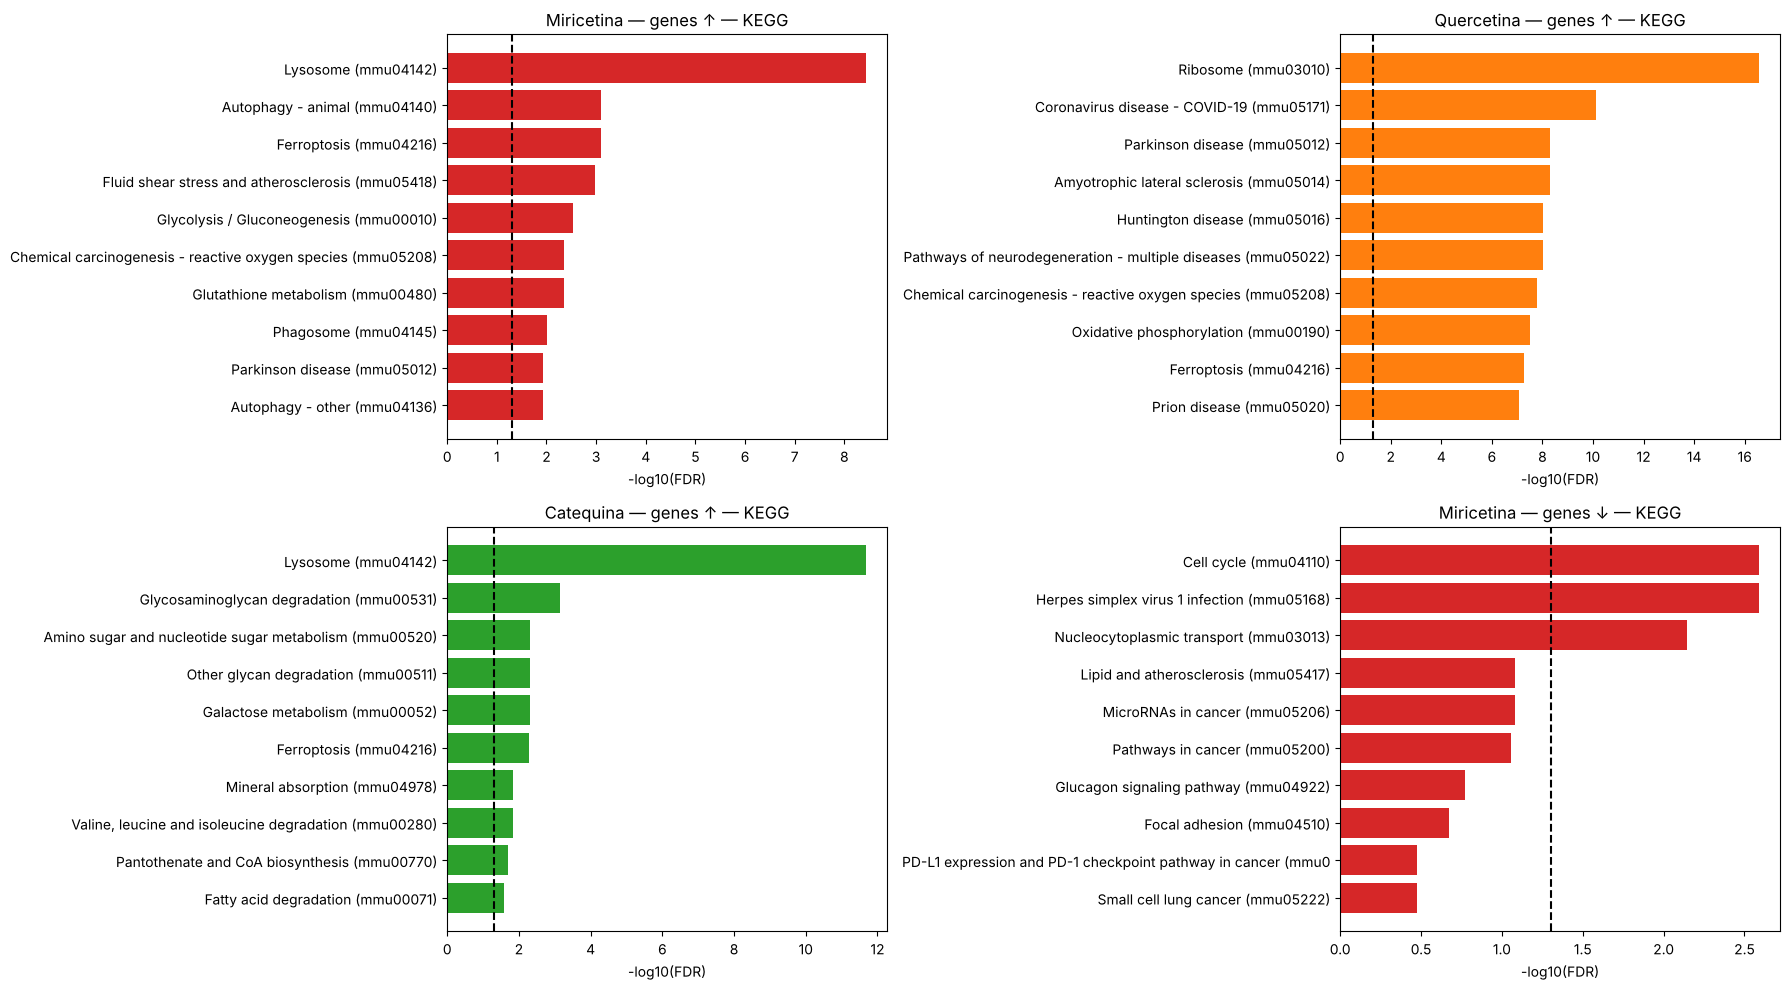

In [25]:
# Acá grafico los 10 términos más enriquecidos en cuatro casos que elegí.

fig, ax = plt.subplots(2, 2, figsize=(18, 10))
for a, (t, sentido, base) in zip(ax.flat, [('YMS', '↑', 'KEGG'), ('HPS', '↑', 'KEGG'), ('ECS', '↑', 'KEGG'), ('YMS', '↓', 'KEGG')]):
    # Los 10 primeros términos, dados vuelta para que el más importante quede arriba en el
    # gráfico.
    df = tablas_ora[(t, sentido, base)].head(10).iloc[::-1]
    # Barras horizontales. El largo es −log10(FDR): más larga, más significativa.
    a.barh(df.término.str.slice(0, 60), -np.log10(df.padj), color=colores[t])
    # Una línea en FDR = 0,05. Lo que pasa esa línea es significativo.
    a.axvline(-np.log10(0.05), ls='--', c='k'); a.set_xlabel('-log10(FDR)')
    a.set_title(f'{nombres[t]} — genes {sentido} — {base}')
plt.tight_layout(); plt.show()

In [26]:
# En esta celda repito el análisis del paper para la catequina, con y sin los genes
# contaminantes, y miro qué genes sostienen los términos "lipídicos".

# Reproducción del análisis del paper para catequina: criterio permisivo, con y sin contaminantes
r = resultados['ECS']
# El criterio del paper. Usa pvalue, no padj.
genes_paper = r[(r.pvalue < 0.05) & (r.log2FoldChange > 1)].index
universo_completo = set(conteos_f.index)
# Las bases de datos con todos los genes, incluidos los contaminantes, para reproducir al
# paper.
bases_completas = {'KEGG': armar_diccionario('pathway', 'pathway_description', universo=universo_completo),
                   'GO': armar_diccionario('GO_ID', 'GO_term', universo=universo_completo)}
for etiqueta, genes, U, B in [('CON contaminantes', genes_paper, universo_completo, bases_completas),
                              ('SIN contaminantes', [g for g in genes_paper if g not in genes_contaminantes], universo, bases)]:
    print(f'\n### Catequina, genes ↑ (criterio del paper) {etiqueta}: {len(genes)} genes')
    for b in ['KEGG', 'GO']:
        df = ora(genes, U, B[b])
        print(f'-- {b}:'); print(df.head(6)[['término', 'genes_en_lista', 'p', 'padj']].round(5).to_string(index=False))

# ¿Qué genes sostienen los términos "lipídicos" que quedan sin los contaminantes?
genes_sin = set(genes_paper) - set(genes_contaminantes)
for termino in ['PPAR signaling pathway (mmu03320)', 'Fat digestion and absorption (mmu04975)']:
    gs = sorted(genes_sin & bases['KEGG'][termino])
    print(f'\n{termino}: {gs}')
    print(pd.DataFrame({'r con puntaje de contaminación': r_puntaje[gs].round(2), 'descripción': desc[gs]}).to_string())
    print(conteos.loc[gs].to_string())


### Catequina, genes ↑ (criterio del paper) CON contaminantes: 73 genes
-- KEGG:
                                           término  genes_en_lista       p    padj
                   Pancreatic secretion (mmu04972)              16 0.00000 0.00000
       Protein digestion and absorption (mmu04974)              12 0.00000 0.00000
           Fat digestion and absorption (mmu04975)               6 0.00000 0.00000
Neuroactive ligand-receptor interaction (mmu04080)               5 0.00003 0.00020
    Complement and coagulation cascades (mmu04610)               4 0.00012 0.00055
                Glycerolipid metabolism (mmu00561)               4 0.00019 0.00075
-- GO:
                                              término  genes_en_lista   p    padj
      serine-type endopeptidase activity (GO:0004252)              11 0.0 0.00000
          serine-type peptidase activity (GO:0008236)              10 0.0 0.00000
collagen-containing extracellular matrix (GO:0062023)              12 0.0 0.00000
  

**¿Qué se observa?**
- Un núcleo común a los cuatro flavonoides: en todos, el término más enriquecido entre los genes que suben es Lisosoma (KEGG y GO), acompañado de autofagia en miricetina y dihidromiricetina. Y entre los genes que bajan aparecen ciclo celular, cromosoma y división celular (catequina, miricetina, dihidromiricetina). O sea: los macrófagos expuestos a flavonoides activan su maquinaria de degradación (lisosoma/autofagia) y frenan la proliferación. Tiene sentido biológico: una célula que recibe compuestos reactivos prioriza "limpiar y defenderse" antes que dividirse. Esto el paper no lo reporta.
- El módulo antioxidante, graduado: en miricetina aparecen ferroptosis (vía KEGG que incluye *Hmox1, Gclm, Slc7a11, Slc40a1*), metabolismo del glutatión, metabolismo de porfirinas (degradación del hemo), "especies reactivas de oxígeno" y, en GO, respuesta al estrés oxidativo. La quercetina muestra los mismos términos antioxidantes (ferroptosis, glutatión, glutatión peroxidasa) y además un fuerte aumento de genes ribosomales y de fosforilación oxidativa (traducción y energía), una firma propia. La dihidromiricetina tiene lisosoma, autofagia, ferroptosis y glutatión con menor significancia. La catequina tiene lisosoma fuerte pero los términos antioxidantes apenas pasan el umbral.
- Catequina, reproduciendo el criterio del paper y CON contaminantes: aparecen exactamente los términos que usan los autores para proponer su mecanismo: actividad triglicérido lipasa, digestión de grasas y proteínas, secreción pancreática y también "matriz extracelular con colágeno" (que el paper usa para hablar de remodelado de matriz). Los genes responsables son enzimas pancreáticas (*Cela1, Cela2a, Cela3b, Prss2, Try4*…) y proteínas plasmáticas.
- SIN contaminantes, esos términos desaparecen o quedan sostenidos por 2–3 genes. La "vía de señalización PPAR" queda apoyada solo en *Apoa5, Fabp1* y *Pck1*: genes de hígado e intestino, con 1 a 27 lecturas, cuya expresión también sigue al puntaje de contaminación (r ≈ 0,7, por debajo del umbral de 0,8). Lo mismo pasa con "cascadas de complemento y coagulación", sostenida por proteínas plasmáticas que fabrica el hígado. No son genes de un macrófago activando PPAR.

Como conclusión de esta sección, el enriquecimiento de "metabolismo lipídico" y de "matriz extracelular" en catequina, que son la base del mecanismo CD36 → PPAR propuesto en el paper, se explica por ARN de tejido digestivo contaminante y no por una respuesta del macrófago. En cambio, la respuesta real de los macrófagos a los flavonoides es lisosomal/autofágica + antioxidante + antiproliferativa.

## 12. Puesta a prueba de la hipótesis del paper (CD36 → PPAR → M2)

**Objetivo:** mirar directamente los genes que el paper usa como evidencia y ver si se sostienen con un análisis estadístico estricto.

**Por qué lo hago:** Un reanálisis crítico tiene que contrastar las afirmaciones concretas, gen por gen. El paper menciona: subida de *Arg1, Ace, Ace2, Il10, Mrc2, Ppara, Ppard* (M2 / PPAR) y bajada de *Tnfaip6, Tnfaip8, Cd80, Cxcl9* (M1), junto con el rol de *Cd36*. Si el mecanismo fuera real, se esperarían cambios consistentes y significativos al menos en catequina.

**Método:** tabla de log2FC y padj para esos genes y para marcadores clásicos M1/M2 en los 4 tratamientos. Si un gen no pasó el filtro de expresión (< 10 lecturas en 3 muestras) lo marqué como "no expresado": no se puede afirmar que cambie algo que la célula casi no expresa.

In [27]:
# Acá reviso, uno por uno, los genes que el paper usa como evidencia.

# Un diccionario con cada gen y su rol (M1, M2, PPAR, Nrf2).
genes_paper = {'Cd36': 'receptor (eje propuesto)', 'Pparg': 'PPAR', 'Ppara': 'PPAR', 'Ppard': 'PPAR',
               'Arg1': 'M2', 'Mrc1': 'M2 (CD206)', 'Mrc2': 'M2', 'Il10': 'M2', 'Ace': 'M2 (paper)', 'Ace2': 'M2 (paper)',
               'Tnfaip6': 'M1 (paper)', 'Tnfaip8': 'M1 (paper)', 'Cd80': 'M1', 'Cxcl9': 'M1', 'Nos2': 'M1', 'Tnf': 'M1',
               'Hmox1': 'Nrf2', 'Nqo1': 'Nrf2', 'Gclm': 'Nrf2'}
filas = []
for g, rol in genes_paper.items():
    # El promedio de lecturas crudas del gen. Me dice si el gen realmente se expresa.
    fila = {'gen': g, 'rol': rol, 'lecturas promedio (crudas)': round(conteos.loc[g].mean(), 1) if g in conteos.index else 0}
    for t in ['ECS', 'HPS', 'YMS', 'EQYMS']:
        r = resultados[t]
        if g not in r.index: fila[nombres[t]] = 'no expresado'
        else:
            pa = r.loc[g, 'padj']; estrella = '*' if (pd.notna(pa) and pa < 0.05) else ''
            # Si no, escribe el log2FC con signo (:+.2f = con signo y 2 decimales) y agrega
            # un asterisco * si padj < 0,05.
            fila[nombres[t]] = f"{r.loc[g, 'log2FoldChange']:+.2f}{estrella}"
    filas.append(fila)
tabla_paper = pd.DataFrame(filas).set_index('gen')
print('Valores = log2FC vs control;  * = padj < 0,05')
tabla_paper

Valores = log2FC vs control;  * = padj < 0,05


,rol,lecturas promedio (crudas),Catequina,Quercetina,Miricetina,Dihidromiricetina
gen,,,,,,
Cd36,receptor (eje propuesto),6344.1,-0.27*,+0.31*,+0.22*,+0.22
Pparg,PPAR,7.3,-0.38,-0.32,-0.23,+0.25
Ppara,PPAR,1.5,no expresado,no expresado,no expresado,no expresado
Ppard,PPAR,1745.4,+0.18,+0.25*,+0.36*,+0.15
Arg1,M2,4.5,+1.36,+0.29,+0.44,-0.28
Mrc1,M2 (CD206),32.3,-0.09,-0.33,+0.16,+0.11
Mrc2,M2,2.2,no expresado,no expresado,no expresado,no expresado
Il10,M2,2.1,no expresado,no expresado,no expresado,no expresado
Ace,M2 (paper),2.3,no expresado,no expresado,no expresado,no expresado


**¿Qué se observa?**
- Varios de los genes que el paper cita como evidencia (Ppara, Il10, Ace, Ace2, Mrc2, Tnfaip6, Cxcl9) no pasan el filtro mínimo de expresión: tienen menos de 10 lecturas en casi todas las muestras. Con 37 millones de lecturas por muestra, eso significa que prácticamente no se expresan en estos macrófagos; cualquier "fold change" sobre esos números es ruido.
- Arg1 tiene un log2FC de +1,36 con catequina, pero parte de ~4 lecturas promedio y DESeq2 no le asigna significancia: es un cambio de "3 a 8 lecturas", no una polarización M2.
- Cd36 es un gen bien expresado pero cambia muy poco y baja levemente con catequina (log2FC = -0,27, significativo), que es lo contrario de lo que propone el mecanismo; con quercetina y miricetina sube levemente. Pparg apenas se expresa (~7 lecturas) y *Ppard* sube un poco con quercetina y miricetina, pero no con catequina.
- Los marcadores M1 tampoco cambian de forma consistente. La única coincidencia con el paper es *Tnfaip8*, que baja levemente con catequina (log2FC = -0,29); *Cd80* baja algo con quercetina, y *Nos2* y *Tnf* no cambian significativamente con ningún tratamiento.
- En cambio, los genes de Nrf2 muestran efectos grandes y significativos en quercetina, miricetina y dihidromiricetina.

En resumen, para H2: con estos datos no hay evidencia transcriptómica sólida del eje CD36 → PPAR → M2 para catequina. Esto no prueba que el mecanismo no exista (el paper tiene otros experimentos, como ELISA de IL-10 con inhibidor de CD36), pero sí muestra que la parte de RNA-seq que lo sostiene es frágil y está afectada por la contaminación.

## 13. Machine learning: ¿se puede reconocer el tratamiento a partir del transcriptoma?

**Objetivo:** usar aprendizaje supervisado para (1) medir qué tan distinguible es cada tratamiento con su perfil de expresión completo y (2) obtener, de forma multivariada, qué genes son más útiles para distinguirlos, y compararlos con los de la expresión diferencial (que es univariada: gen por gen).

**Por qué lo hago:** Un programa "aprende" si mejora en una tarea al incorporar experiencia; memorizar no es aprender, generalizar sí. Acá el problema es de clasificación: dado un objeto (una muestra con 500 características = genes), asignarle una etiqueta de un conjunto finito (el tratamiento).

El desafío de estos datos: tengo 15 muestras y miles de genes (muchas más variables que observaciones). Esto hace muy fácil sobreajustar. Por eso:
- No separé train/test 70/30 como en las prácticas: con 3 réplicas por clase quedarían clases sin ejemplos en el test. Usé validación cruzada "deja uno fuera" (LOOCV): se entrena con 14 muestras, se predice la que quedó afuera, y se repite 15 veces. Cada predicción es sobre una muestra que el modelo nunca vio.
- Usé solo los 500 genes más variables (selección no supervisada: no usa las etiquetas, así que no "filtra" información del resultado).
- Comparé modelos de complejidad creciente: árbol de decisión → random forest → SVM → red neuronal.

**Preparación:** matriz VST, etiquetas codificadas numéricamente (LabelEncoder, como en la práctica de redes) y dos versiones de los datos: con y sin el módulo contaminante.

**Qué es una matriz de confusión:** una tabla donde las filas son la clase real y las columnas, lo que predijo el modelo. Los aciertos están en la diagonal. Todo lo que está fuera de la diagonal es un error.

In [28]:
# En esta celda preparo todo para el machine learning: los datos, las etiquetas, el método
# de validación y una función para dibujar matrices de confusión.

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

# Función que se queda con los 500 genes más variables y da vuelta la tabla (muestras como
# filas).
def matriz_ml(vst_matriz, n_top=500):
    var = vst_matriz.var(axis=1).sort_values(ascending=False)
    return vst_matriz.loc[var.index[:n_top]].T          # muestras x genes

# Dos versiones de los datos, con y sin contaminantes.
X_con = matriz_ml(vst)                # con contaminantes
X_sin = matriz_ml(vst_limpio)         # sin contaminantes
# Convierte los nombres de grupo en números (ECS = 0, EQYMS = 1, etc.). Los modelos trabajan
# con números.
codificador = LabelEncoder()
y = codificador.fit_transform(metadatos.loc[X_sin.index, 'grupo'])
clases = codificador.classes_
print('Codificación de clases:', dict(zip(clases, range(len(clases)))))
print('Forma de X:', X_sin.shape, '→ 15 muestras, 500 características')
# El método de validación: LOOCV, "dejar uno afuera".
loo = LeaveOneOut()

# Una función para dibujar la matriz de confusión de cualquier modelo.
def matriz_confusion(y_real, y_pred, titulo, ax):
    cm = pd.DataFrame(confusion_matrix(y_real, y_pred, labels=range(len(clases))),
                      index=[nombres[c] for c in clases], columns=[nombres[c] for c in clases])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(f'{titulo}\nexactitud = {accuracy_score(y_real, y_pred):.0%}', fontsize=10)
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')

Codificación de clases: {'ECS': 0, 'EQYMS': 1, 'HPS': 2, 'PBS': 3, 'YMS': 4}
Forma de X: (15, 500) → 15 muestras, 500 características


### 13.1 Árbol de decisión: el modelo más interpretable

**Teoría.** Los árboles de decisión dividen los datos recursivamente buscando subconjuntos lo más puros posible, medido con la entropía (o Gini). Su ventaja es que son fáciles de interpretar: el nodo raíz es la característica más importante para la primera división. Su desventaja es que sobreajustan y son inestables. Usé el criterio entropía como en la práctica, pero con `min_samples_leaf=2` por el tamaño muestral.

Entrené el árbol con y sin los genes contaminantes. Es un control: si la catequina solo se pudiera reconocer por la contaminación, el árbol "con" la clasificaría bien y el árbol "sin" fallaría con ella.

**Cómo funciona un árbol:** hace preguntas del tipo "¿el gen X tiene un valor mayor a tal número?", y según la respuesta va hacia una rama u otra hasta llegar a una decisión (la clase).

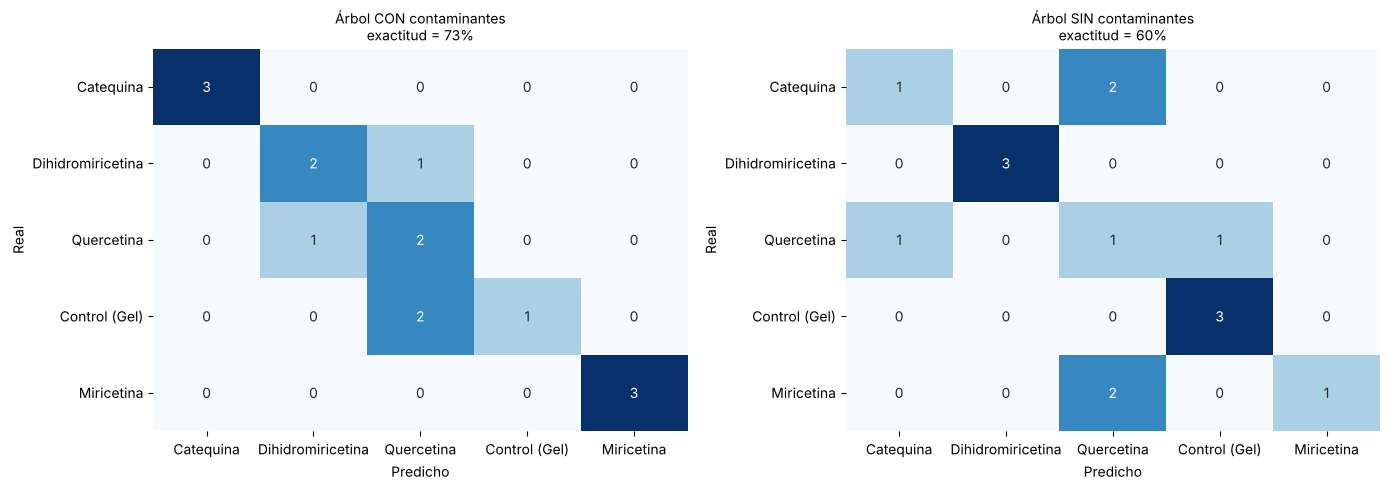

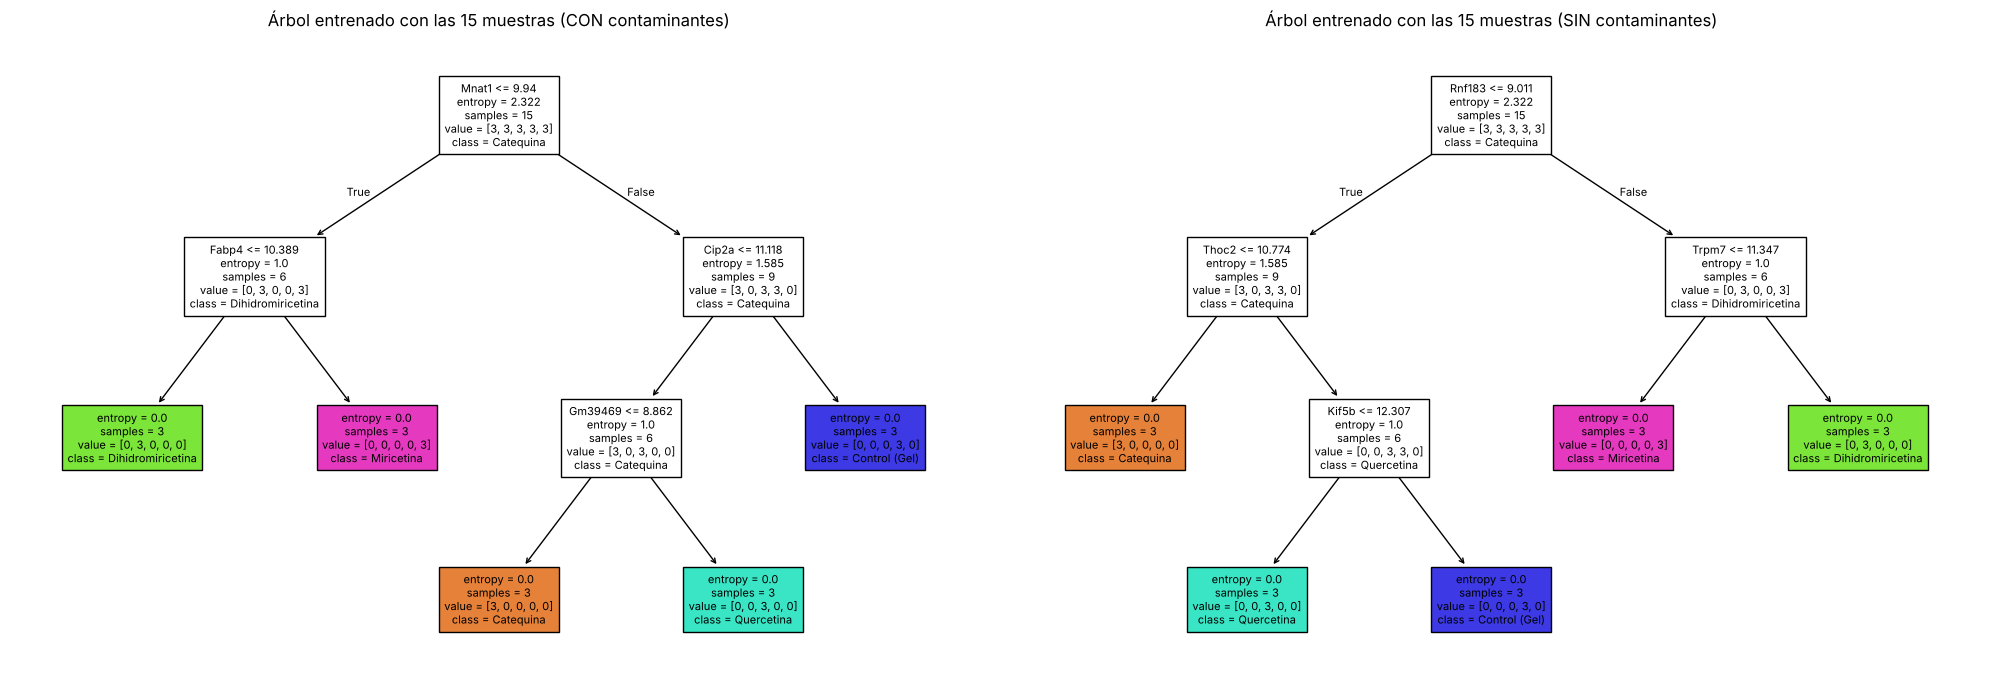

Gen del nodo raíz CON contaminantes: Mnat1
Gen del nodo raíz SIN contaminantes: Rnf183
Genes usados por el árbol sin contaminantes: ['Trpm7', 'Rnf183', 'Kif5b', 'Thoc2']


In [29]:
# Acá entreno un árbol de decisión, con y sin genes contaminantes, lo evalúo y lo dibujo.

# Elige cada pregunta para que las ramas queden lo más "puras" posible (con una sola clase),
# medido con la entropía.
arbol_params = dict(criterion='entropy', min_samples_leaf=2, random_state=SEMILLA)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (X, etiqueta) in zip(ax, [(X_con, 'Árbol CON contaminantes'), (X_sin, 'Árbol SIN contaminantes')]):
    # Hace toda la LOOCV y devuelve la predicción de cada muestra cuando quedó afuera.
    pred = cross_val_predict(DecisionTreeClassifier(**arbol_params), X, y, cv=loo)
    matriz_confusion(y, pred, etiqueta, a)
plt.tight_layout(); plt.show()

# Entreno un árbol final con las 15 muestras, solo para dibujarlo e interpretarlo (no para
# evaluarlo).
arbol_con = DecisionTreeClassifier(**arbol_params).fit(X_con, y)
arbol_sin = DecisionTreeClassifier(**arbol_params).fit(X_sin, y)
fig, ax = plt.subplots(1, 2, figsize=(20, 7))
for a, (m, X, t) in zip(ax, [(arbol_con, X_con, 'CON contaminantes'), (arbol_sin, X_sin, 'SIN contaminantes')]):
    plot_tree(m, feature_names=X.columns, class_names=[nombres[c] for c in clases], filled=True, ax=a, fontsize=8)
    a.set_title(f'Árbol entrenado con las 15 muestras ({t})')
plt.tight_layout(); plt.show()
print('Gen del nodo raíz CON contaminantes:', X_con.columns[arbol_con.tree_.feature[0]])
print('Gen del nodo raíz SIN contaminantes:', X_sin.columns[arbol_sin.tree_.feature[0]])
print('Genes usados por el árbol sin contaminantes:', [X_sin.columns[i] for i in set(arbol_sin.tree_.feature) if i >= 0])

**¿Qué se observa?**
- Un árbol entrenado con las 15 muestras usa apenas 4 genes para separar los 5 grupos, y ninguno es contaminante, ni siquiera cuando los contaminantes están disponibles. El árbol sin contaminantes usa *Rnf183, Trpm7, Kif5b* y *Thoc2*.
- En validación LOOCV, el árbol acierta solo el 73 % (con contaminantes) y el 60 % (sin ellos), y se equivoca en muestras distintas en cada caso (por ejemplo, sin contaminantes confunde dos réplicas de catequina y dos de miricetina con quercetina). Es la inestabilidad que predice la teoría: con 3 muestras por clase y hojas de 2, alcanza con sacar una muestra para que el árbol elija otro gen en la raíz y cambie todas sus reglas. La diferencia entre 73 % y 60 % no indica que la contaminación "ayude": son 2 muestras de diferencia en un modelo inestable.
- Conclusión: el árbol es útil para interpretar (qué genes elegiría como reglas), pero no para predecir con tan pocos datos. Por eso paso a modelos de conjunto.

### 13.2 Random Forest: un conjunto de árboles más estable

**Teoría.** Random Forest combina muchos árboles entrenados con dos fuentes de aleatoriedad: cada árbol ve una muestra bootstrap (con reemplazo) y en cada nodo solo se considera un subconjunto aleatorio de genes. Así los árboles quedan poco correlacionados, la votación mayoritaria es más precisa y estable y se reduce el sobreajuste. Además da dos cosas útiles: el error out-of-bag (OOB) (cada árbol se evalúa con las muestras que no entraron en su bootstrap, sin necesidad de un test aparte) y la importancia de cada característica. Usé 1000 árboles y OOB, como en la práctica.

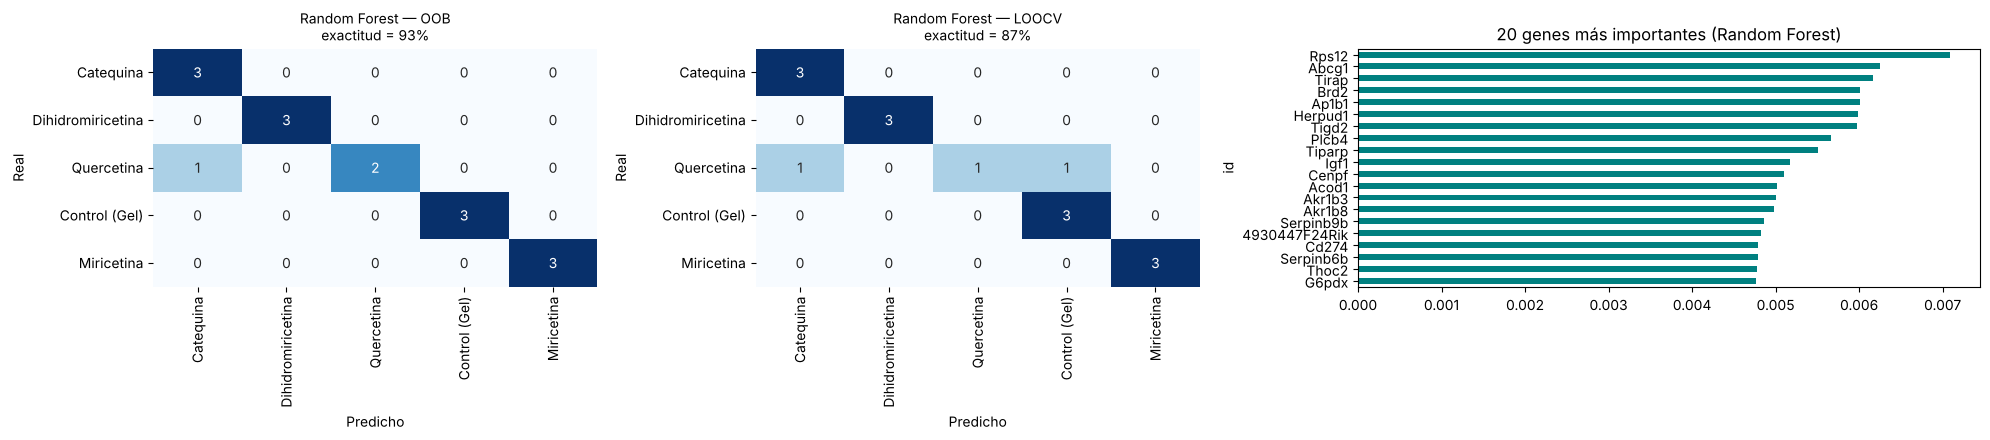

Exactitud OOB: 93%
De los 30 genes más importantes del RF, 30 también son diferenciales (padj<0,05) en algún tratamiento
30 genes más importantes: Rps12, Abcg1, Tirap, Brd2, Ap1b1, Herpud1, Tigd2, Plcb4, Tiparp, Igf1, Cenpf, Acod1, Akr1b3, Akr1b8, Serpinb9b, 4930447F24Rik, Cd274, Serpinb6b, Thoc2, G6pdx, Zfp729a, Oasl2, Ipo7, Olfml3, P2ry10b, Haus3, Mat2a, Ddx3y, Cdc23, Ptgr1


In [30]:
# En esta celda entreno un Random Forest (muchos árboles que votan juntos), lo evalúo y veo
# qué genes considera más importantes.

# Un bosque de 1000 árboles. oob_score=True activa la evaluación OOB.
rf = RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=SEMILLA)
rf.fit(X_sin, y)
# La predicción OOB de cada muestra.
pred_oob = rf.classes_[np.argmax(rf.oob_decision_function_, axis=1)]
# Además evalúo con LOOCV, igual que los otros modelos, para comparar justo.
pred_loo_rf = cross_val_predict(RandomForestClassifier(n_estimators=500, random_state=SEMILLA), X_sin, y, cv=loo)

fig, ax = plt.subplots(1, 3, figsize=(20, 4.5), gridspec_kw={'width_ratios': [1, 1, 1.4]})
matriz_confusion(y, pred_oob, 'Random Forest — OOB', ax[0])
matriz_confusion(y, pred_loo_rf, 'Random Forest — LOOCV', ax[1])
# La importancia de cada gen: cuánto ayuda a separar las clases en el bosque.
imp = pd.Series(rf.feature_importances_, index=X_sin.columns).sort_values(ascending=False)
imp.head(20).iloc[::-1].plot.barh(ax=ax[2], color='teal'); ax[2].set_title('20 genes más importantes (Random Forest)')
plt.tight_layout(); plt.show()
print(f'Exactitud OOB: {rf.oob_score_:.0%}')

top_rf = imp.head(30).index
de_union = set.union(*sig_sets.values())
print(f'De los 30 genes más importantes del RF, {sum(g in de_union for g in top_rf)} también son diferenciales (padj<0,05) en algún tratamiento')
print('30 genes más importantes:', ', '.join(top_rf))

**¿Qué se observa?** El Random Forest mejora mucho respecto del árbol único, como predice la teoría: promediar muchos árboles diversos reduce la inestabilidad. La exactitud OOB es 93 % (solo falla HPS-3, clasificada como catequina) y la de LOOCV 87 % (falla además HPS-1, clasificada como control): justo las réplicas de quercetina que ya se veían "corridas" en el PCA y el clustering. La catequina nunca se confunde con el control, lo que confirma que tiene una firma propia aunque no active la defensa antioxidante.

Los 30 genes más importantes son todos genes diferenciales en algún tratamiento. Entre ellos aparecen blancos clásicos de Nrf2 (*Akr1b8, Akr1b3, G6pdx, Ptgr1*), *Acod1* (produce itaconato, un metabolito antiinflamatorio de macrófagos que justamente activa Nrf2), *Abcg1* (exporta colesterol), *Cd274* (PD-L1, inmunorregulador), *Igf1* y genes de proliferación (*Cenpf, Haus3, Cdc23*). Dos enfoques independientes (multivariado y univariado) señalan los mismos genes y los mismos procesos, lo que refuerza el hallazgo.

### 13.3 Máquinas de vectores soporte (SVM)

**Teoría.** Las SVM buscan el hiperplano que separa las clases con el máximo margen, definido por los vectores soporte (los puntos más cercanos a la frontera). Son especialmente eficaces en espacios de alta dimensionalidad, justo mi caso (500 genes, 15 muestras). El parámetro C regula el equilibrio margen/errores: C chico = margen amplio, tolera errores y generaliza mejor; C grande = margen estrecho y riesgo de sobreajuste. Con el kernel se elige la forma de la frontera (lineal, RBF…). Barrí C en escala logarítmica, como en la práctica, pero evaluando cada valor con LOOCV. Estandaricé los genes dentro del pipeline (la SVM trabaja con distancias, así que la escala importa).

**Cómo funciona una SVM:** busca la "frontera" que separa las clases dejando el mayor margen posible entre ellas. El **kernel** define la forma de esa frontera: `linear` es una línea recta (o un plano); `rbf` permite fronteras curvas.

**Qué es C:** controla cuánto castiga los errores en el entrenamiento. C chico: margen amplio, acepta algunos errores, generaliza mejor. C grande: intenta no equivocarse nunca, puede sobreajustar.

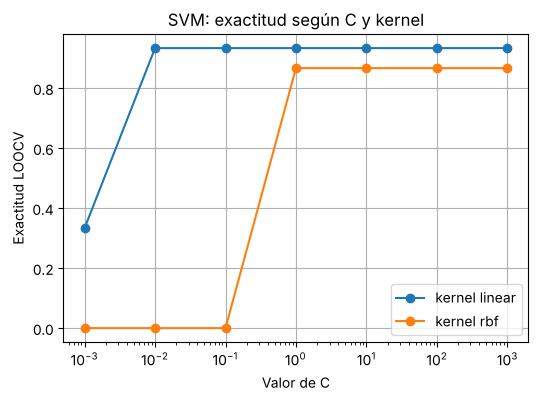

Mejor configuración: kernel=linear, C=0.01, exactitud LOOCV=93%


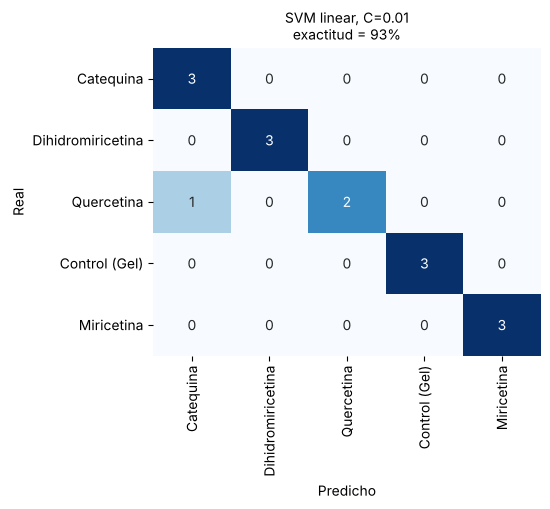

In [31]:
# Acá entreno una SVM probando distintos valores de C y dos tipos de kernel, y me quedo con
# la mejor combinación.

# 7 valores de C repartidos en escala logarítmica: 0,001; 0,01; 0,1; 1; 10; 100; 1000.
valores_C = np.logspace(-3, 3, 7)
resultados_svm = {}
for kernel in ['linear', 'rbf']:
    exactitudes = []
    for C in valores_C:
        # Un "tubo" de dos pasos: primero estandariza los genes y después entrena la SVM. Va
        # junto para que la estandarización se calcule solo con las muestras de
        # entrenamiento en cada vuelta de la LOOCV (si no, estaría "espiando" la muestra de
        # test).
        modelo = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=C))
        exactitudes.append(accuracy_score(y, cross_val_predict(modelo, X_sin, y, cv=loo)))
    resultados_svm[kernel] = exactitudes

plt.figure(figsize=(6, 4))
for k, v in resultados_svm.items(): plt.semilogx(valores_C, v, 'o-', label=f'kernel {k}')
plt.xlabel('Valor de C'); plt.ylabel('Exactitud LOOCV'); plt.title('SVM: exactitud según C y kernel'); plt.grid(True); plt.legend()
plt.show()
# Busca la combinación con mayor exactitud.
mejor_kernel = max(resultados_svm, key=lambda k: max(resultados_svm[k]))
mejor_C = valores_C[int(np.argmax(resultados_svm[mejor_kernel]))]
print(f'Mejor configuración: kernel={mejor_kernel}, C={mejor_C}, exactitud LOOCV={max(resultados_svm[mejor_kernel]):.0%}')
pred_svm = cross_val_predict(make_pipeline(StandardScaler(), SVC(kernel=mejor_kernel, C=mejor_C)), X_sin, y, cv=loo)
fig, ax = plt.subplots(figsize=(5, 4)); matriz_confusion(y, pred_svm, f'SVM {mejor_kernel}, C={mejor_C:g}', ax); plt.show()

**¿Qué se observa?** La SVM lineal llega a 93 % (14 de 15) y se mantiene estable para C entre 0,01 y 1000; la de kernel RBF nunca supera el 87 %. Que alcance un kernel lineal tiene sentido: con 500 dimensiones y 15 puntos casi siempre existe un hiperplano que separa las clases (las SVM son eficaces en alta dimensionalidad), y un kernel más flexible solo agrega riesgo de sobreajuste. Con C muy chico (0,001) el margen es tan amplio que el modelo tolera demasiados errores y termina prediciendo casi siempre la misma clase (exactitud 33 %). El único error es otra vez HPS-3 → catequina.

### 13.4 Red neuronal (Keras): ¿tiene sentido el deep learning con 15 muestras?

**Teoría.** Una red neuronal apila "perceptrones" en capas; cada neurona hace una suma ponderada y aplica una función de activación, y el entrenamiento ajusta los pesos con backpropagation y descenso por gradiente. Son muy potentes porque cada capa aprende representaciones más abstractas, pero tienen muchísimos parámetros. Para combatir el sobreajuste se usa dropout: en cada paso se apaga al azar una fracción de neuronas, lo que obliga a la red a aprender características robustas.

La pregunta honesta acá es si un modelo con decenas de miles de pesos puede generalizar con 14 ejemplos de entrenamiento. Usé una arquitectura chica inspirada en la de la práctica (capas densas con ReLU, Dropout 0,5, salida softmax y pérdida *sparse categorical crossentropy*) y la evalué con la misma LOOCV.

**Cómo funciona una red neuronal:** tiene capas de "neuronas". Cada neurona hace una suma ponderada de sus entradas y aplica una función de activación. Al entrenar, la red ajusta los pesos para equivocarse cada vez menos.

Parámetros entrenables de la red: 34309


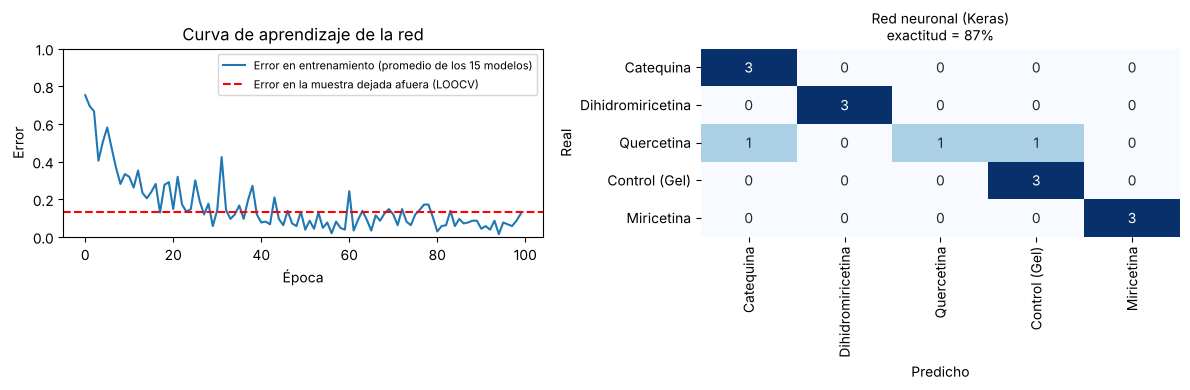

In [32]:
# En esta celda entreno una red neuronal con Keras y la evalúo con LOOCV.

import tensorflow as tf
from tensorflow.keras import layers, models
tf.get_logger().setLevel('ERROR')

def crear_red(n_entradas, n_clases):
    # Fija la semilla para que dé siempre lo mismo.
    tf.keras.utils.set_random_seed(SEMILLA)
    # La entrada: 500 genes.
    red = models.Sequential([layers.Input(shape=(n_entradas,)),
                             # Una capa de 64 neuronas con activación ReLU (deja pasar los
                             # valores positivos y pone en cero los negativos).
                             layers.Dense(64, activation='relu'), layers.Dropout(0.5),
                             layers.Dense(32, activation='relu'), layers.Dropout(0.5),
                             layers.Dense(n_clases, activation='softmax')])
    red.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return red

Xn = X_sin.values
pred_red, historiales = np.zeros(len(y), dtype=int), []
for tr, te in loo.split(Xn):
    esc = StandardScaler().fit(Xn[tr])
    red = crear_red(Xn.shape[1], len(clases))
    h = red.fit(esc.transform(Xn[tr]), y[tr], epochs=100, batch_size=4, verbose=0)
    historiales.append(h.history['accuracy'])
    pred_red[te] = np.argmax(red.predict(esc.transform(Xn[te]), verbose=0), axis=1)

print('Parámetros entrenables de la red:', red.count_params())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(1 - np.mean(historiales, axis=0), label='Error en entrenamiento (promedio de los 15 modelos)')
ax[0].axhline(1 - accuracy_score(y, pred_red), c='r', ls='--', label='Error en la muestra dejada afuera (LOOCV)')
ax[0].set_xlabel('Época'); ax[0].set_ylabel('Error'); ax[0].set_ylim(0, 1); ax[0].legend(fontsize=8)
ax[0].set_title('Curva de aprendizaje de la red')
matriz_confusion(y, pred_red, 'Red neuronal (Keras)', ax[1])
plt.tight_layout(); plt.show()

**¿Qué se observa?** La red tiene 34.309 parámetros para aprender de 14 muestras y logra 87 % en LOOCV: se equivoca en HPS-3 (→ catequina) y en HPS-2 (→ control). La curva de aprendizaje muestra el efecto del dropout: el error de entrenamiento baja pero queda "ruidoso" (entre 0 y 0,1 en las últimas épocas), porque en cada paso se apaga la mitad de las neuronas y la red no puede memorizar perfectamente; eso es lo que limita el sobreajuste. Aun así, la red no supera a la SVM lineal, que tiene muchos menos parámetros, es determinística, más rápida y más fácil de interpretar. Además, al depender de la inicialización aleatoria de los pesos, su resultado puede variar levemente si se ejecuta en otra computadora. Con pocos datos, el deep learning no es la herramienta adecuada.

### 13.5 Comparación de modelos

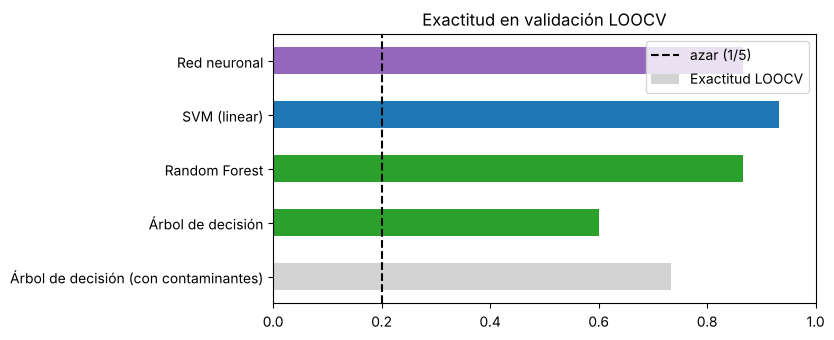

Árbol de decisión (con contaminantes)    0.73
Árbol de decisión                        0.60
Random Forest                            0.87
SVM (linear)                             0.93
Red neuronal                             0.87
Name: Exactitud LOOCV, dtype: float64

In [33]:
# Acá junto la exactitud de todos los modelos en un solo gráfico para compararlos.

# Una lista con el nombre de cada modelo y su exactitud en LOOCV.
comparacion = pd.Series({
    'Árbol de decisión (con contaminantes)': accuracy_score(y, cross_val_predict(DecisionTreeClassifier(**arbol_params), X_con, y, cv=loo)),
    'Árbol de decisión': accuracy_score(y, cross_val_predict(DecisionTreeClassifier(**arbol_params), X_sin, y, cv=loo)),
    'Random Forest': accuracy_score(y, pred_loo_rf),
    f'SVM ({mejor_kernel})': accuracy_score(y, pred_svm),
    'Red neuronal': accuracy_score(y, pred_red)}, name='Exactitud LOOCV')
ax = comparacion.plot.barh(figsize=(7, 3.5), color=['lightgrey', 'tab:green', 'tab:green', 'tab:blue', 'tab:purple'])
ax.axvline(0.2, ls='--', c='k', label='azar (1/5)'); ax.set_xlim(0, 1); ax.legend(); plt.title('Exactitud en validación LOOCV'); plt.show()
comparacion.round(2)

**¿Qué se observa?** Todos los modelos superan claramente al azar (20 %): el transcriptoma contiene información suficiente para reconocer el tratamiento, incluso la catequina (que nunca se confunde con el control en los modelos de conjunto). El orden de desempeño sigue la teoría: árbol único (60–73 %) < Random Forest ≈ red neuronal (87 %) < SVM lineal (93 %). Lo más informativo es que todos los modelos de conjunto, la SVM y la red se equivocan en la misma muestra, HPS-3, a la que clasifican como catequina. Cuando cuatro algoritmos distintos coinciden, el problema no es del modelo sino de la muestra: HPS-3 es una réplica de quercetina con un perfil global parecido al de catequina, aunque su firma Nrf2 sí es la de quercetina (sección 10). Puede ser variabilidad biológica o un problema técnico (por ejemplo, contaminación cruzada entre pocillos); con estos datos no se puede saber.

Lo que aprendí de esta comparación es que, con pocas muestras, el modelo adecuado es el más simple que resuelve el problema (acá, la SVM lineal), la validación tiene que hacerse sobre datos que el modelo no vio, y los errores sistemáticos son una herramienta de control de calidad.

## 14. Del ratón al humano: análisis de secuencias, alineamiento y filogenia de HO-1

**Objetivo:** evaluar la relevancia traslacional del hallazgo (H3): las proteínas efectoras de la respuesta que encontré en macrófagos de ratón ¿son prácticamente iguales en humano?

**Por qué lo hago:** Todo el experimento se hizo con una línea murina, pero el objetivo final es tratar heridas en personas. Si la proteína efectora estuviera poco conservada, extrapolar sería arriesgado. Para eso usé:
- Bases de datos de proteínas: UniProt (Swiss-Prot = entradas revisadas manualmente), descargando las secuencias en formato FASTA.
- Biopython para manipular las secuencias (longitud, composición, búsqueda de motivos).
- Alineamiento de secuencias: global (Needleman-Wunsch; compara las secuencias completas, adecuado para ortólogos de longitud parecida) y local (Smith-Waterman; busca la región más parecida, que es lo que hace BLAST). Usé la matriz de sustitución BLOSUM62 y penalidades de gap.
- Filogenia molecular: reconstruir las relaciones evolutivas de HO-1 entre varias especies a partir de las distancias entre secuencias.

Elegí HO-1 (Hmox1) porque fue el gen con mayor efecto en miricetina, y agregué NQO1 y GCLM, otros dos blancos de Nrf2 que subieron de forma significativa.

**Método:** se intenta descargar las secuencias desde la API de UniProt; si no hay conexión, se usa una copia de las mismas entradas (los números de acceso de UniProt están en los encabezados FASTA).

**Qué es el formato FASTA:** una línea que empieza con `>` y tiene el nombre, y abajo la secuencia en letras (cada letra es un aminoácido).

In [34]:
# En esta celda descargo de UniProt las secuencias de proteína de HO-1, NQO1 y GCLM en
# varias especies.

from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqUtils.ProtParam import ProteinAnalysis
from Bio.Align import PairwiseAligner, substitution_matrices

accesiones = {'HMOX1_HUMAN': 'P09601', 'HMOX1_MOUSE': 'P14901', 'HMOX1_RAT': 'P06762', 'HMOX1_BOVIN': 'Q5E9F2',
              'HMOX1_PIG': 'P32394', 'HMOX1_PONAB': 'Q5R7E3', 'HMOX1_CHICK': 'P14791',
              'NQO1_HUMAN': 'P15559', 'NQO1_MOUSE': 'Q64669', 'GCLM_HUMAN': 'P48507', 'GCLM_MOUSE': 'O09172'}

# Una copia de las secuencias escrita en el código (es el texto largo entre comillas
# triples).
FASTA_RESPALDO = """>sp|P09601|HMOX1_HUMAN Heme oxygenase 1 OS=Homo sapiens
MERPQPDSMPQDLSEALKEATKEVHTQAENAEFMRNFQKGQVTRDGFKLVMASLYHIYVALEEEIERNKESPVFAPVYFPEELHRKAALEQDLAFWYGPRWQEVIPYTPAMQRYVKRLHEVGRTEPELLVAHAYTRYLGDLSGGQVLKKIAQKALDLPSSGEGLAFFTFPNIASATKFKQLYRSRMNSLEMTPAVRQRVIEEAKTAFLLNIQLFEELQELLTHDTKDQSPSRAPGLRQRASNKVQDSAPVETPRGKPPLNTRSQAPLLRWVLTLSFLVATVAVGLYAM
>sp|P14901|HMOX1_MOUSE Heme oxygenase 1 OS=Mus musculus
MERPQPDSMPQDLSEALKEATKEVHIQAENAEFMKNFQKGQVSREGFKLVMASLYHIYTALEEEIERNKQNPVYAPLYFPEELHRRAALEQDMAFWYGPHWQEIIPCTPATQHYVKRLHEVGRTHPELLVAHAYTRYLGDLSGGQVLKKIAQKAMALPSSGEGLAFFTFPNIDSPTKFKQLYRARMNTLEMTPEVKHRVTEEAKTAFLLNIELFEELQVMLTEEHKDQSPSQMASLRQRPASLVQDTAPAETPRGKPQISTSSSQTPLLQWVLTLSFLLATVAVGIYAM
>sp|P06762|HMOX1_RAT Heme oxygenase 1 OS=Rattus norvegicus
MERPQLDSMSQDLSEALKEATKEVHIRAENSEFMRNFQKGQVSREGFKLVMASLYHIYTALEEEIERNKQNPVYAPLYFPEELHRRAALEQDMAFWYGPHWQEAIPYTPATQHYVKRLHEVGGTHPELLVAHAYTRYLGDLSGGQVLKKIAQKAMALPSSGEGLAFFTFPSIDNPTKFKQLYRARMNTLEMTPEVKHRVTEEAKTAFLLNIELFEELQALLTEEHKDQSPSQTEFLRQRPASLVQDTTSAETPRGKSQISTSSSQTPLLRWVLTLSFLLATVAVGIYAM
>sp|Q5E9F2|HMOX1_BOVIN Heme oxygenase 1 OS=Bos taurus
MERPQPDSSMPQDLSEALKEATKEVHTQAENAEFMKNFQKGELTQEGFKLVMASLYHIYVALEEEIERNKENPVYTPLYFPEELHRRASLEQDMAFWYGPRWQEAIPYTQATKRYVQRLQEVGRTEPELLVAHAYTRYLGDLSGGQVLKKIAQKALNLPSSGEGLAFFTFPNIASATKFKQLYRSRMNTLEMTPEVRQRVLDEAKTAFLLNIQLFEELQGLLTQKAKDHDPLQAPELHRRAGSKVQDLAPTKASRGKPQPSVLSQAPLLRWVLTLSFLVATVAVGLYAM
>sp|P32394|HMOX1_PIG Heme oxygenase 1 OS=Sus scrofa
MEHSQPNSMPQDLSEALKEATKEVHVQAENAEFMKNFQKGEVTREGFKLVMASLYHIYDALEEEIEHNKENPVYTPLYFPEELHRRAALEQDMAFWYGPRWQEAIPYTQATKRYVRRLQQVGRFEPELLVAHAYTRYMGDLSGGQVLKKIAQKALDLPSSGEGLAFFTFPNVANATKFKQLYRSRMNTLEMTPEVKQRVLEEAKTAFLLNIQLFEEVQELLTQDTKDQRPSQASDIRKRAGSRVQDSTPVTTPRGKPQLSVLSQVPLIRWVLTLSFLVATVAMGLYAM
>sp|Q5R7E3|HMOX1_PONAB Heme oxygenase 1 OS=Pongo abelii
MERPQPDSMPQDLSEALKEATKEVHTQAENAEFMRNFQKGQVTREGFKLVMASLYHIYVALEEEIEHNKESPVFAPVYFPEELHRKAALEQDLAFWYGPRWQEVIPYTPAMQRYVKRLHEVGRTEPELLVAHAYTRYLGDLSGGQVLKKIAQKALGLPSSGEGLAFFTFPNIASATKFKQLYRSRMNSLEMTPAVRQRVIEEAKTAFLLNIQLFEELQELLTHDTKDQSPSRAPGLRQRASNKAQDSAPVETPRGKTPLNTHSQAPLLRWVLTLSFLVATVAVGLYAM
>sp|P14791|HMOX1_CHICK Heme oxygenase 1 OS=Gallus gallus
METSQPHNAESMSQDLSELLKEATKEVHEQAENTPFMKNFQKGQVSLHEFKLVTASLYFIYSALEEEIERNKDNPVYAPVYFPMELHRKAALEKDLEYFYGSNWRAEIPCPEATQKYVERLHVVGKKHPELLVAHAYTRYLGDLSGGQVLKKIAQKALQLPSTGEGLAFFTFDGVSNATKFKQLYRSRMNALEMDHATKKRVLEEAKKAFLLNIQVFEALQKLVSKSQENGHAVQPKAELRTRSVNKSHENSPAAGKESERTSRMQADMLTTSPLVRWLLALGFIATTVAVGLFAM
>sp|P15559|NQO1_HUMAN NAD(P)H dehydrogenase [quinone] 1 OS=Homo sapiens
MVGRRALIVLAHSERTSFNYAMKEAAAAALKKKGWEVVESDLYAMNFNPIISRKDITGKLKDPANFQYPAESVLAYKEGHLSPDIVAEQKKLEAADLVIFQFPLQWFGVPAILKGWFERVFIGEFAYTYAAMYDKGPFRSKKAVLSITTGGSGSMYSLQGIHGDMNVILWPIQSGILHFCGFQVLEPQLTYSIGHTPADARIQILEGWKKRLENIWDETPLYFAPSSLFDLNFQAGFLMKKEVQDEEKNKKFGLSVGHHLGKSIPTDNQIKARK
>sp|Q64669|NQO1_MOUSE NAD(P)H dehydrogenase [quinone] 1 OS=Mus musculus
MAARRALIVLAHSEKTSFNYAMKEAAVEALKKRGWEVLESDLYAMNFNPIISRNDITGELKDSKNFQYPSESSLAYKEGRLSPDIVAEHKKLEAADLVIFQFPLQWFGVPAILKGWFERVLVAGFAYTYAAMYDNGPFQNKKTLLSITTGGSGSMYSLQGVHGDMNVILWPIQSGILRFCGFQVLEPQLVYSIGHTPPDARMQILEGWKKRLETVWEETPLYFAPSSLFDLNFQAGFLMKKEVQEEQKKNKFGLSVGHHLGKSIPADNQIKARK
>sp|P48507|GCLM_HUMAN Glutamate-cysteine ligase regulatory subunit OS=Homo sapiens
MGTDSRAAKALLARARTLHLQTGNLLNWGRLRKKCPSTHSEELHDCIQKTLNEWSSQINPDLVREFPDVLECTVSHAVEKINPDEREEMKVSAKLFIVESNSSSSTRSAVDMACSVLGVAQLDSVIIASPPIEDGVNLSLEHLQPYWEELENLVQSKKIVAIGTSDLDKTQLEQLYQWAQVKPNSNQVNLASCCVMPPDLTAFAKQFDIQLLTHNDPKELLSEASFQEALQESIPDIQAHEWVPLWLLRYSVIVKSRGIIKSKGYILQAKRRGS
>sp|O09172|GCLM_MOUSE Glutamate-cysteine ligase regulatory subunit OS=Mus musculus
MGTDSRAAGALLARASTLHLQTGNLLNWGRLRKKCPSTHSEELRDCIQKTLNEWSSQISPDLVREFPDVLECTMSHAVEKINPDEREEMKVSAKLFIVGSNSSSSTRSAVDMACSVLGVAQLDSVIMASPPIEDGVNLSLEHLQPYWEELENLVQSKKIVAIGTSDLDKTQLEQLYQWAQVKPNSNQVNLASCCVMPPDLTAFAKQFDIQLLTHNDPKELLSEASFQEALQESIPDIEAQDWVPLWLLRYSVIVKSRGIIKSKGYILQAKRRGS
"""

try:
    url = 'https://rest.uniprot.org/uniprotkb/stream?format=fasta&query=' + '+OR+'.join(f'accession:{a}' for a in accesiones.values())
    texto = urllib.request.urlopen(url, timeout=20).read().decode()
    origen = 'API de UniProt'
except Exception:
    texto, origen = FASTA_RESPALDO, 'copia de respaldo de UniProt'
secuencias = {}
for registro in SeqIO.parse(io.StringIO(texto), 'fasta'):
    # Del encabezado sp|P09601|HMOX1_HUMAN se queda con la tercera parte, HMOX1_HUMAN.
    nombre = registro.id.split('|')[2] if '|' in registro.id else registro.id
    # En UniProt, GCLM figura con otro nombre (GSH0), y lo cambio para que sea más claro.
    nombre = nombre.replace('GSH0_', 'GCLM_')
    # Guarda cada secuencia en un diccionario.
    secuencias[nombre] = registro.seq
print(f'Secuencias obtenidas desde: {origen}')
for n, s in secuencias.items(): print(f'{n:13s} {len(s):4d} aa   {str(s[:30])}...')

Secuencias obtenidas desde: copia de respaldo de UniProt
HMOX1_HUMAN    288 aa   MERPQPDSMPQDLSEALKEATKEVHTQAEN...
HMOX1_MOUSE    289 aa   MERPQPDSMPQDLSEALKEATKEVHIQAEN...
HMOX1_RAT      289 aa   MERPQLDSMSQDLSEALKEATKEVHIRAEN...
HMOX1_BOVIN    289 aa   MERPQPDSSMPQDLSEALKEATKEVHTQAE...
HMOX1_PIG      288 aa   MEHSQPNSMPQDLSEALKEATKEVHVQAEN...
HMOX1_PONAB    288 aa   MERPQPDSMPQDLSEALKEATKEVHTQAEN...
HMOX1_CHICK    296 aa   METSQPHNAESMSQDLSELLKEATKEVHEQ...
NQO1_HUMAN     274 aa   MVGRRALIVLAHSERTSFNYAMKEAAAAAL...
NQO1_MOUSE     274 aa   MAARRALIVLAHSEKTSFNYAMKEAAVEAL...
GCLM_HUMAN     274 aa   MGTDSRAAKALLARARTLHLQTGNLLNWGR...
GCLM_MOUSE     274 aa   MGTDSRAAGALLARASTLHLQTGNLLNWGR...


In [35]:
# Acá analizo la secuencia de HO-1 con funciones básicas de Biopython: cuento, busco un
# motivo y calculo propiedades.

# Manipulación básica de secuencias con Biopython: composición, motivos y propiedades
# Guardo la HO-1 de ratón y la de humano en dos variables.
ho1_m, ho1_h = secuencias['HMOX1_MOUSE'], secuencias['HMOX1_HUMAN']
print('Histidinas en HO-1 ratón / humano:', ho1_m.count('H'), '/', ho1_h.count('H'))
# Un pedacito de secuencia que contiene la histidina 25, el aminoácido que sostiene el
# hierro del hemo.
motivo = 'KEATKEVH'   # región que contiene la His25 proximal que coordina el hierro del hemo
print(f'Motivo {motivo}: posición en ratón = {ho1_m.find(motivo)}, en humano = {ho1_h.find(motivo)}')
print('Residuo 25 (contando desde 1) en ratón y humano:', ho1_m[24], ho1_h[24])
print('Extremo C-terminal (ancla transmembrana):', ho1_m[-23:], '|', ho1_h[-23:])
for n in ['HMOX1_MOUSE', 'HMOX1_HUMAN']:
    # Calcula la masa molecular (molecular_weight, la divido por 1000 para pasarla a kDa) y
    # el punto isoeléctrico (isoelectric_point, el pH en el que la proteína no tiene carga).
    pa = ProteinAnalysis(str(secuencias[n]))
    print(f'{n}: masa = {pa.molecular_weight()/1000:.1f} kDa, pI = {pa.isoelectric_point():.2f}')

Histidinas en HO-1 ratón / humano: 10 / 6
Motivo KEATKEVH: posición en ratón = 17, en humano = 17
Residuo 25 (contando desde 1) en ratón y humano: H H
Extremo C-terminal (ancla transmembrana): PLLQWVLTLSFLLATVAVGIYAM | PLLRWVLTLSFLVATVAVGLYAM
HMOX1_MOUSE: masa = 32.9 kDa, pI = 6.08
HMOX1_HUMAN: masa = 32.8 kDa, pI = 7.89


**Conceptos:**

- **Alineamiento global:** alinea las dos secuencias completas, de punta a punta. Sirve cuando son de largo parecido.
- **Alineamiento local:** busca solo la región que más se parece. Sirve cuando comparten un dominio pero el resto es distinto.
- **BLOSUM62:** una tabla de puntajes que dice qué tan "aceptable" es cambiar un aminoácido por otro. Cambiar por uno parecido (por ejemplo, leucina por isoleucina) suma puntos; cambiar por uno muy distinto resta.
- **Gaps (huecos):** espacios que se agregan para que las secuencias encajen. Abrir un hueco cuesta −10 y alargarlo, −0,5. Así se prefieren pocos huecos largos en vez de muchos cortos.

In [36]:
# En esta celda alineo las proteínas de ratón y humano y calculo qué porcentaje de
# aminoácidos son idénticos.

# Cargo la matriz de sustitución BLOSUM62.
blosum62 = substitution_matrices.load('BLOSUM62')
def alinear(a, b, modo='global'):
    # Creo el alineador y le digo que use BLOSUM62 para puntuar.
    al = PairwiseAligner(); al.substitution_matrix = blosum62
    # Los costos de los huecos y si es global o local.
    al.open_gap_score, al.extend_gap_score, al.mode = -10, -0.5, modo
    # Hace el alineamiento y se queda con el mejor.
    aln = al.align(a, b)[0]
    c = aln.counts()
    largo = c.identities + c.mismatches + c.gaps
    return aln, c.identities / largo, aln.score

filas = []
for prot in ['HMOX1', 'NQO1', 'GCLM']:
    m, h = secuencias[f'{prot}_MOUSE'], secuencias[f'{prot}_HUMAN']
    _, id_g, sc_g = alinear(m, h, 'global')
    aln_l, id_l, sc_l = alinear(m, h, 'local')
    filas.append({'proteína': prot, 'largo ratón': len(m), 'largo humano': len(h),
                  'identidad global (%)': round(100 * id_g, 1), 'score global': sc_g,
                  'identidad local (%)': round(100 * id_l, 1), 'score local': sc_l})
tabla_cons = pd.DataFrame(filas).set_index('proteína'); print(tabla_cons)

aln_ho1, _, _ = alinear(ho1_m, ho1_h, 'global')
print('\nAlineamiento global HO-1 ratón (arriba) vs humano (abajo), primeros 120 residuos:')
print(str(aln_ho1).split('\n\n')[0]); print(str(aln_ho1).split('\n\n')[1])

          largo ratón  largo humano  identidad global (%)  score global  \
proteína                                                                  
HMOX1             289           288                  82.0        1236.0   
NQO1              274           274                  86.5        1269.0   
GCLM              274           274                  96.4        1356.0   

          identidad local (%)  score local  
proteína                                    
HMOX1                    82.0       1236.0  
NQO1                     86.5       1269.0  
GCLM                     96.4       1356.0  

Alineamiento global HO-1 ratón (arriba) vs humano (abajo), primeros 120 residuos:
target            0 MERPQPDSMPQDLSEALKEATKEVHIQAENAEFMKNFQKGQVSREGFKLVMASLYHIYTA
                  0 |||||||||||||||||||||||||.||||||||.|||||||.|.|||||||||||||.|
query             0 MERPQPDSMPQDLSEALKEATKEVHTQAENAEFMRNFQKGQVTRDGFKLVMASLYHIYVA
target           60 LEEEIERNKQNPVYAPLYFPEELHRRAALEQDMAFWYGPHWQEIIPCTPATQH

           Humano  Orangután  Ratón   Rata   Vaca  Cerdo  Gallina
Humano      0.000      0.021  0.180  0.201  0.163  0.174    0.361
Orangután   0.021      0.000  0.187  0.204  0.170  0.177    0.369
Ratón       0.180      0.187  0.000  0.066  0.200  0.211    0.375
Rata        0.201      0.204  0.066  0.000  0.224  0.221    0.381
Vaca        0.163      0.170  0.200  0.224  0.000  0.145    0.392
Cerdo       0.174      0.177  0.211  0.221  0.145  0.000    0.388
Gallina     0.361      0.369  0.375  0.381  0.392  0.388    0.000


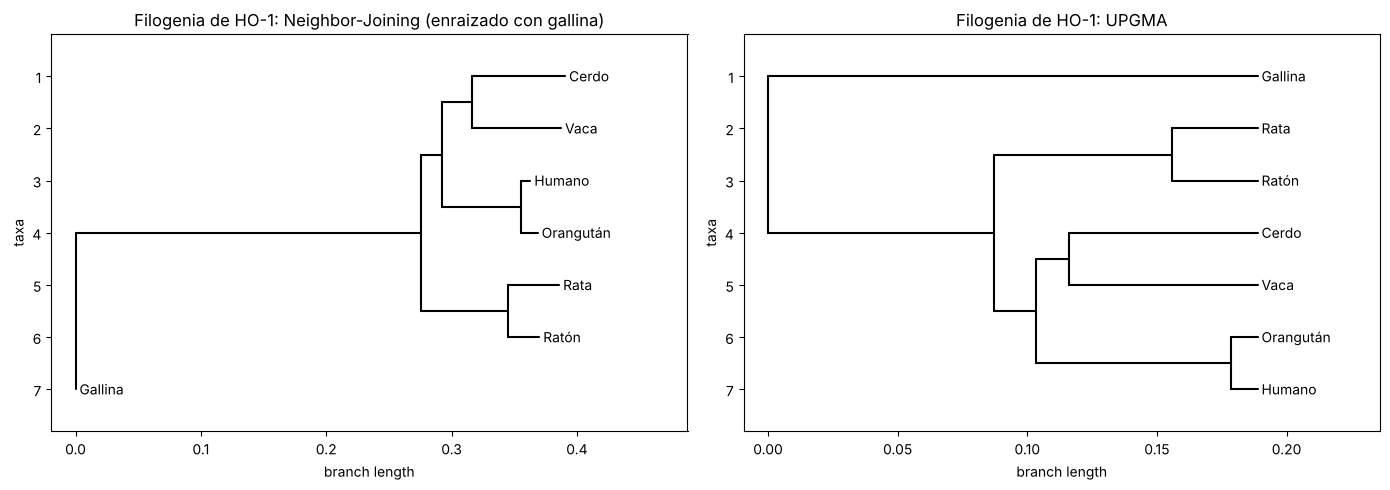

In [37]:
# Acá armo árboles filogenéticos de la proteína HO-1 en 7 especies.

from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor
from Bio import Phylo

especies = {'HMOX1_HUMAN': 'Humano', 'HMOX1_PONAB': 'Orangután', 'HMOX1_MOUSE': 'Ratón', 'HMOX1_RAT': 'Rata',
            'HMOX1_BOVIN': 'Vaca', 'HMOX1_PIG': 'Cerdo', 'HMOX1_CHICK': 'Gallina'}
nombres_sp = list(especies.values()); claves = list(especies.keys())
matriz = []
for i in range(len(claves)):
    fila = []
    for j in range(i + 1):
        fila.append(0.0 if i == j else 1 - alinear(secuencias[claves[i]], secuencias[claves[j]], 'global')[1])
    matriz.append(fila)
# La matriz de distancias en el formato que pide Biopython.
dm = DistanceMatrix(nombres_sp, matriz)
print(pd.DataFrame([[dm[a, b] for b in nombres_sp] for a in nombres_sp], index=nombres_sp, columns=nombres_sp).round(3))

constructor = DistanceTreeConstructor()
# Árbol Neighbor-Joining: une primero las especies más cercanas, pero permite que cada rama
# evolucione a distinta velocidad.
arbol_nj = constructor.nj(dm)
# Pone la raíz en la gallina. Es el grupo externo: un ave, más lejana que todos los
# mamíferos, que sirve para orientar el árbol.
arbol_nj.root_with_outgroup('Gallina')     # el ave es el grupo externo de los mamíferos
# Árbol UPGMA: asume que todas las ramas evolucionan a la misma velocidad (reloj molecular).
arbol_upgma = constructor.upgma(dm)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (arb, t) in zip(ax, [(arbol_nj, 'Neighbor-Joining (enraizado con gallina)'), (arbol_upgma, 'UPGMA')]):
    for clado in arb.find_clades():
        if not clado.is_terminal(): clado.name = None
    Phylo.draw(arb, axes=a, do_show=False); a.set_title(f'Filogenia de HO-1: {t}')
plt.tight_layout(); plt.show()

**¿Qué se observa?**
- HO-1 de ratón y de humano comparten 82 % de identidad en el alineamiento global, y la región catalítica es casi idéntica: el motivo *KEATKEVH* está en la misma posición y la His25, que coordina el hierro del hemo, se conserva en ambas especies, igual que el segmento hidrofóbico C-terminal que ancla la enzima al retículo. Las diferencias se concentran en la región C-terminal no catalítica (por eso cambia el punto isoeléctrico, 6,1 vs 7,9, sin cambiar la masa: ~32,9 kDa). NQO1 (86,5 %) y GCLM (96,4 %) están aún más conservadas. El alineamiento local da exactamente las mismas identidades que el global porque son ortólogos de largo casi igual que se alinean de punta a punta: la región "más parecida" es toda la proteína.
- El árbol filogenético agrupa correctamente humano + orangután (primates), ratón + rata (roedores) y vaca + cerdo, con la gallina (ave) como grupo externo de los mamíferos. Pero hay un detalle interesante: en ambos árboles los primates quedan más cerca de vaca y cerdo que de los roedores, cuando en el árbol de las especies los primates están más emparentados con los roedores. Esto pasa porque los roedores acumulan sustituciones más rápido (tiempo generacional corto): sus ramas son más largas y "se alejan" de todos. Es un ejemplo de que un árbol de un solo gen no siempre coincide con el árbol de las especies.
- UPGMA asume un reloj molecular (misma velocidad de evolución en todos los linajes) y NJ no. Que ambos coincidan acá indica que la topología es robusta para este gen, pero la diferencia de velocidad en roedores muestra que el supuesto de reloj de UPGMA no se cumple del todo.
- Para mi pregunta, lo importante es la distancia ratón–humano (0,18): HO-1 de ratón es tan distinta de la humana como la de cerdo o vaca, pero conserva intactos los residuos funcionales.

En resumen, para H3: las proteínas efectoras de la respuesta que encontré están fuertemente conservadas en humanos, y la vía Nrf2/KEAP1 está conservada en mamíferos. Es razonable proponer que la activación de esta defensa antioxidante por miricetina sea relevante en células humanas, aunque obviamente hay que validarlo experimentalmente.

## 15. Discusión y conclusiones

### Respuesta a la pregunta de investigación
1. Hay una respuesta común y una parte graduada (H1 se cumple). Los cuatro flavonoides mueven el transcriptoma en la misma dirección (log2FC correlacionados): activan el lisosoma y la autofagia y frenan la proliferación. Encima de ese núcleo común, quercetina, miricetina y dihidromiricetina activan un programa de defensa antioxidante tipo Nrf2 (*Hmox1, Nqo1, Gclm, Txnrd1, Srxn1, Slc7a11, Gsta2*) con intensidad miricetina > quercetina > dihidromiricetina, coherente con la reactividad química de cada molécula. La catequina no activa esa defensa (su puntaje Nrf2 es igual al del control) y produce cambios de baja magnitud, aunque tiene una firma propia reconocible.
2. El mecanismo propuesto en el paper no tiene respaldo transcriptómico sólido (H2 no se cumple). Las muestras contienen ARN de tejido digestivo (páncreas exocrino, hígado e intestino), con máxima intensidad justo en las tres réplicas de catequina. Ese artefacto explica el enriquecimiento de "triglicérido lipasa", "digestión de grasas" y "matriz extracelular con colágeno" que sostiene el eje CD36 → PPAR → M2. Sin los genes contaminantes, esos términos desaparecen; *Cd36* incluso baja levemente con catequina y varios marcadores M2/PPAR citados casi no se expresan en estas células.
3. Los efectores de la respuesta están conservados en humanos (H3 se cumple). HO-1 (82 %), NQO1 (86,5 %) y GCLM (96,4 %) conservan sus residuos funcionales, lo que apoya el interés traslacional de la miricetina como activador de la defensa antioxidante en heridas diabéticas.

### Coherencia entre métodos
La misma conclusión surge de enfoques independientes: el PCA y el clustering (no supervisados) muestran un eje principal "antioxidante ↑ / proliferación ↓" con la miricetina en el extremo; la expresión diferencial (univariada) y el Random Forest (multivariado) señalan los mismos genes; el análisis funcional con bases de datos los ubica en lisosoma, autofagia, glutatión y estrés oxidativo; y los cuatro clasificadores coinciden en reconocer los tratamientos y en marcar la misma réplica dudosa (HPS-3). Esta convergencia es lo que da confianza al resultado.

### Limitaciones
- Tamaño muestral: 3 réplicas por grupo limitan la potencia estadística y obligan a usar validación cruzada LOOCV en el machine learning; los porcentajes de exactitud tienen mucha incertidumbre.
- Un solo tiempo (24 h) y una línea celular murina: no se sabe si la respuesta persiste ni cómo es en macrófagos primarios o humanos.
- La contaminación no se pudo confirmar a nivel de lecturas: trabajé con la matriz de conteos. La asignación de los códigos ECS/HPS/YMS/EQYMS a cada flavonoide se infirió de los nombres de las muestras.
- La réplica HPS-3 se comporta de forma atípica (parecida a catequina en el perfil global), lo que reduce la confianza en las conclusiones específicas de quercetina más allá de su firma antioxidante.
- El transcriptoma no es el fenotipo: un ARNm que sube no garantiza más proteína ni más actividad.

### Próximos pasos propuestos
- Confirmar la contaminación con las lecturas crudas: descargar los FASTQ desde SRA, mapear en Galaxy las lecturas no asignadas al genoma de ratón y clasificarlas por especie/tejido con BLAST (o un clasificador taxonómico como en metagenómica). Eso diría de qué organismo y tejido viene el ARN pancreático.
- Validar a nivel de proteína (proteómica / Western blot) que HO-1 y NQO1 aumentan con miricetina.
- Metabolómica: medir glutatión reducido/oxidado y especies reactivas de oxígeno para confirmar funcionalmente la activación de la defensa antioxidante.
- Repetir con macrófagos humanos (por ejemplo THP-1 o derivados de monocitos) y en presencia de un estímulo inflamatorio, que es el contexto real de la herida diabética.

## 16. Mapa de conceptos de la materia aplicados en este trabajo

| Tema de la materia | Cómo se aplicó en este proyecto | Sección |
|---|---|---|
| Manejo de datos en Colab con Python y pandas | Carga, DataFrames, estadística descriptiva y visualización | 3, 4 |
| Bases de datos bioinformáticas | GEO (datos), anotación NCBI Gene, KEGG, Gene Ontology, Reactome, UniProt | 3, 11, 14 |
| Genómica (secuenciación, calidad Phred, Galaxy) | Flujo de trabajo que generó los conteos (fastp → HISAT2 → HTSeq) y propuesta de verificación en Galaxy | 1, 15 |
| Transcriptómica (RNA-seq, expresión diferencial) | Normalización, DESeq2, volcanes, firmas génicas | 5, 9, 10 |
| Metagenómica | Detección de ARN de otro tejido y propuesta de clasificación taxonómica de lecturas | 6, 15 |
| Proteómica y metabolómica | Propuestas de validación a nivel proteína y metabolitos | 15 |
| Análisis de secuencias con Biopython | Lectura de FASTA, conteo, búsqueda de motivos, propiedades de proteínas | 14 |
| Alineamiento de secuencias (global, local, BLAST) | Needleman-Wunsch y Smith-Waterman con BLOSUM62 ratón vs humano | 14 |
| Filogenia molecular | Matriz de distancias y árboles NJ y UPGMA de HO-1 en 7 especies | 14 |
| Minería de datos: preparación, normalización, visualización | Limpieza, filtro, valores faltantes, codificación de clases, VST, mapas de calor | 4, 5, 6 |
| PCA | Varianza explicada, cargas, efecto de la contaminación | 7 |
| Clustering (jerárquico y K-means) | Enlaces single/complete/average, K-means y ARI; clustering de genes | 8, 10 |
| Árboles de decisión | Entropía, interpretación del nodo raíz, aprendizaje del artefacto | 13.1 |
| Random Forest | Bootstrap, OOB, importancia de características | 13.2 |
| SVM | Kernels, barrido del parámetro C | 13.3 |
| Redes neuronales y deep learning | Red densa en Keras con dropout, curva de aprendizaje y sobreajuste | 13.4 |

## 17. Referencias

- Zeng Q., Du S., Yuan R., Zeng Y., Li X., Wu Y.-W., Chen K., Tao L., Tang Z., Deng X. (2025). Self-Healing Hydrogel Dressing with Solubilized Flavonoids for Whole Layer Regeneration of Diabetic Wound. *Advanced Healthcare Materials* 14: 2500734. DOI: 10.1002/adhm.202500734. Datos: GEO GSE260761.
- Love M.I., Huber W., Anders S. (2014). Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. *Genome Biology* 15: 550.
- Muzellec B. et al. (2023). PyDESeq2: a python package for bulk RNA-seq differential expression analysis. *Bioinformatics* 39: btad547.
- Cock P.J.A. et al. (2009). Biopython: freely available Python tools for computational molecular biology and bioinformatics. *Bioinformatics* 25: 1422-1423.
- Pedregosa F. et al. (2011). Scikit-learn: Machine learning in Python. *JMLR* 12: 2825-2830.
- Benjamini Y., Hochberg Y. (1995). Controlling the false discovery rate. *J. R. Stat. Soc. B* 57: 289-300.
- Ma Q. (2013). Role of Nrf2 in oxidative stress and toxicity. *Annual Review of Pharmacology and Toxicology* 53: 401-426.
- The UniProt Consortium (2023). UniProt: the Universal Protein Knowledgebase in 2023. *Nucleic Acids Research* 51: D523-D531.